# Valence & Arousal Prediction from Ecological Essays (SemEval-2026 Task 2)

## Overview
Predicting a writer's self-reported emotional **valence** (−2 to +2) and **arousal** (0 to 2) from short, time-stamped texts that the same people wrote repeatedly over time (SemEval-2026 Task 2, Subtask 1). Because each user contributes a sequence of entries, the task combines text regression with per-user temporal modeling.

## Dataset
SemEval-2026 Task 2, Subtask 1 training release (`train_subtask1.csv`): 2,764 texts from 137 users. About half are lists of feeling words and half are short essays, and each is labeled with valence and arousal. Source: [semeval2026task2/EmotionValArouTimeVariation2026](https://github.com/semeval2026task2/EmotionValArouTimeVariation2026) (`datasets/TRAIN_RELEASE_3SEP2025/`).

## Approach
- Exploratory analysis of label imbalance, text length and per-user activity
- Baseline: DistilBERT (`distilbert-base-uncased`) with a linear regression head, trained with an inverse-frequency weighted MSE loss
- User-based 80/20 split and user-based 5-fold cross-validation, so that no user appears in both training and validation
- Sequence model: an LSTM over each user's chronologically ordered DistilBERT [CLS] embeddings, with the previous entry's valence/arousal as an extra input
- Ablations (user embeddings, history), a domain-adversarial (DANN) variant, error analysis, a seen vs. unseen user evaluation and an autoregressive inference pipeline

## Key results
**Official test set** (1,737 texts from 91 users, scored against the gold labels released by the organizers): official composite within/between-person correlation, computed with `evaluate_test_set.py`:

| Model | Valence | Arousal |
|---|---|---|
| DistilBERT baseline | 0.644 | 0.434 |
| LSTM + history (final model) | 0.666 | 0.444 |

**Validation** (Pearson correlation on 572 texts from 28 held-out users):

| Model | Valence | Arousal | Average |
|---|---|---|---|
| DistilBERT baseline | 0.780 | 0.563 | 0.671 |
| LSTM + history (final model) | 0.794 | 0.576 | 0.685 |

User-based 5-fold cross-validation of the baseline: average correlation 0.571 ± 0.057.

# Exploratory Data Analysis (EDA)

This section examines the structure of the dataset, the label distributions, text lengths and per-user activity, to identify the challenges that shape the modeling choices later on.

In [39]:
# =============================================================================
# EXPLORATORY DATA ANALYSIS (EDA)
# =============================================================================
# This section provides a comprehensive analysis of the dataset including:
# 1. Dataset Overview and Basic Statistics
# 2. Valence Distribution Analysis
# 3. Arousal Distribution Analysis
# 4. Text Length Distribution
# 5. User Entry Distribution (Imbalance Analysis)
# 6. Valence-Arousal Relationship (2D Analysis)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set plotting style for consistency
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# -----------------------------------------------------------------------------
# 1. LOAD AND INSPECT THE DATASET
# -----------------------------------------------------------------------------
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

# Load the dataset
df = pd.read_csv('train_subtask1.csv')

# Basic information
print(f"\n Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\n Columns: {list(df.columns)}")
print(f"\n Data Types:")
print(df.dtypes)

print(f"\n Basic Statistics:")
print(df.describe())

print(f"\n First 5 Samples:")
display(df.head())

# Check for missing values
print(f"\n Missing Values:")
print(df.isnull().sum())

# -----------------------------------------------------------------------------
# 2. USER STATISTICS
# -----------------------------------------------------------------------------
print("\n" + "=" * 60)
print("USER STATISTICS")
print("=" * 60)

n_users = df['user_id'].nunique()
entries_per_user = df.groupby('user_id').size()

print(f"\n👥 Total Unique Users: {n_users}")
print(f" Total Entries: {len(df)}")
print(f" Entries per User:")
print(f"   - Minimum: {entries_per_user.min()}")
print(f"   - Maximum: {entries_per_user.max()}")
print(f"   - Average: {entries_per_user.mean():.2f}")
print(f"   - Median: {entries_per_user.median():.2f}")
print(f"   - Std Dev: {entries_per_user.std():.2f}")

# -----------------------------------------------------------------------------
# 3. TARGET VARIABLE STATISTICS (Valence & Arousal)
# -----------------------------------------------------------------------------
print("\n" + "=" * 60)
print("TARGET VARIABLE STATISTICS")
print("=" * 60)

print("\n VALENCE (How positive/negative):")
print(f"   Range: [{df['valence'].min()}, {df['valence'].max()}]")
print(f"   Mean: {df['valence'].mean():.3f}")
print(f"   Std: {df['valence'].std():.3f}")
print(f"   Value Counts:")
valence_counts = df['valence'].value_counts().sort_index()
for val, count in valence_counts.items():
    pct = count / len(df) * 100
    print(f"      {int(val):+d}: {count:4d} ({pct:5.1f}%)")

print("\n AROUSAL (Level of activation):")
print(f"   Range: [{df['arousal'].min()}, {df['arousal'].max()}]")
print(f"   Mean: {df['arousal'].mean():.3f}")
print(f"   Std: {df['arousal'].std():.3f}")
print(f"   Value Counts:")
arousal_counts = df['arousal'].value_counts().sort_index()
for val, count in arousal_counts.items():
    pct = count / len(df) * 100
    print(f"      {int(val)}: {count:4d} ({pct:5.1f}%)")

# -----------------------------------------------------------------------------
# 4. TEXT LENGTH STATISTICS
# -----------------------------------------------------------------------------
print("\n" + "=" * 60)
print("TEXT LENGTH STATISTICS")
print("=" * 60)

df['text_length'] = df['text'].astype(str).apply(len)
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

print(f"\nCharacter Length:")
print(f"   Min: {df['text_length'].min()}")
print(f"   Max: {df['text_length'].max()}")
print(f"   Mean: {df['text_length'].mean():.1f}")
print(f"   Median: {df['text_length'].median():.1f}")

print(f"\nWord Count:")
print(f"   Min: {df['word_count'].min()}")
print(f"   Max: {df['word_count'].max()}")
print(f"   Mean: {df['word_count'].mean():.1f}")
print(f"   Median: {df['word_count'].median():.1f}")

# Check is_words column distribution
if 'is_words' in df.columns:
    print(f"\n📋 Entry Type (is_words column):")
    is_words_counts = df['is_words'].value_counts()
    for val, count in is_words_counts.items():
        pct = count / len(df) * 100
        label = "Single Words" if val else "Full Essays"
        print(f"   {label}: {count} ({pct:.1f}%)")

print("\nEDA Statistics Complete!")
print("=" * 60)

DATASET OVERVIEW

 Dataset Shape: 2764 rows × 8 columns

 Columns: ['user_id', 'text_id', 'text', 'timestamp', 'collection_phase', 'is_words', 'valence', 'arousal']

 Data Types:
user_id               int64
text_id               int64
text                 object
timestamp            object
collection_phase      int64
is_words               bool
valence             float64
arousal             float64
dtype: object

 Basic Statistics:
           user_id      text_id  collection_phase      valence      arousal
count  2764.000000  2764.000000       2764.000000  2764.000000  2764.000000
mean     75.847323  2574.388205          5.154124     0.216715     0.751085
std      54.044222  1577.827958          2.294176     1.292142     0.753985
min       1.000000     1.000000          1.000000    -2.000000     0.000000
25%      33.000000  1081.750000          3.000000    -1.000000     0.000000
50%      63.000000  2670.500000          7.000000     0.000000     1.000000
75%     124.000000  3939.250000

,user_id,text_id,text,timestamp,collection_phase,is_words,valence,arousal
0,3,251,I ' ve been feeling just fine . Nice and relax...,2021-06-08 12:26:16,1,False,1.0,1.0
1,3,252,I ' ve been feeling pretty good . This is my l...,2021-06-09 13:41:40,1,False,0.0,1.0
2,3,253,Still feeling sick today and sneezing alot wit...,2021-06-11 15:13:48,1,False,1.0,1.0
3,3,254,I ' m still feeling kinda sickly but I powered...,2021-06-12 12:20:03,1,False,1.0,1.0
4,3,255,I ' m feeling so much better today ! Seems lik...,2021-06-13 14:54:41,1,False,2.0,1.0



 Missing Values:
user_id             0
text_id             0
text                0
timestamp           0
collection_phase    0
is_words            0
valence             0
arousal             0
dtype: int64

USER STATISTICS

👥 Total Unique Users: 137
 Total Entries: 2764
 Entries per User:
   - Minimum: 2
   - Maximum: 206
   - Average: 20.18
   - Median: 14.00
   - Std Dev: 27.97

TARGET VARIABLE STATISTICS

 VALENCE (How positive/negative):
   Range: [-2.0, 2.0]
   Mean: 0.217
   Std: 1.292
   Value Counts:
      -2:  369 ( 13.4%)
      -1:  377 ( 13.6%)
      +0:  892 ( 32.3%)
      +1:  538 ( 19.5%)
      +2:  588 ( 21.3%)

 AROUSAL (Level of activation):
   Range: [0.0, 2.0]
   Mean: 0.751
   Std: 0.754
   Value Counts:
      0: 1215 ( 44.0%)
      1: 1022 ( 37.0%)
      2:  527 ( 19.1%)

TEXT LENGTH STATISTICS

Character Length:
   Min: 18
   Max: 1105
   Mean: 158.6
   Median: 56.0

Word Count:
   Min: 5
   Max: 225
   Mean: 32.9
   Median: 11.0

📋 Entry Type (is_words column):


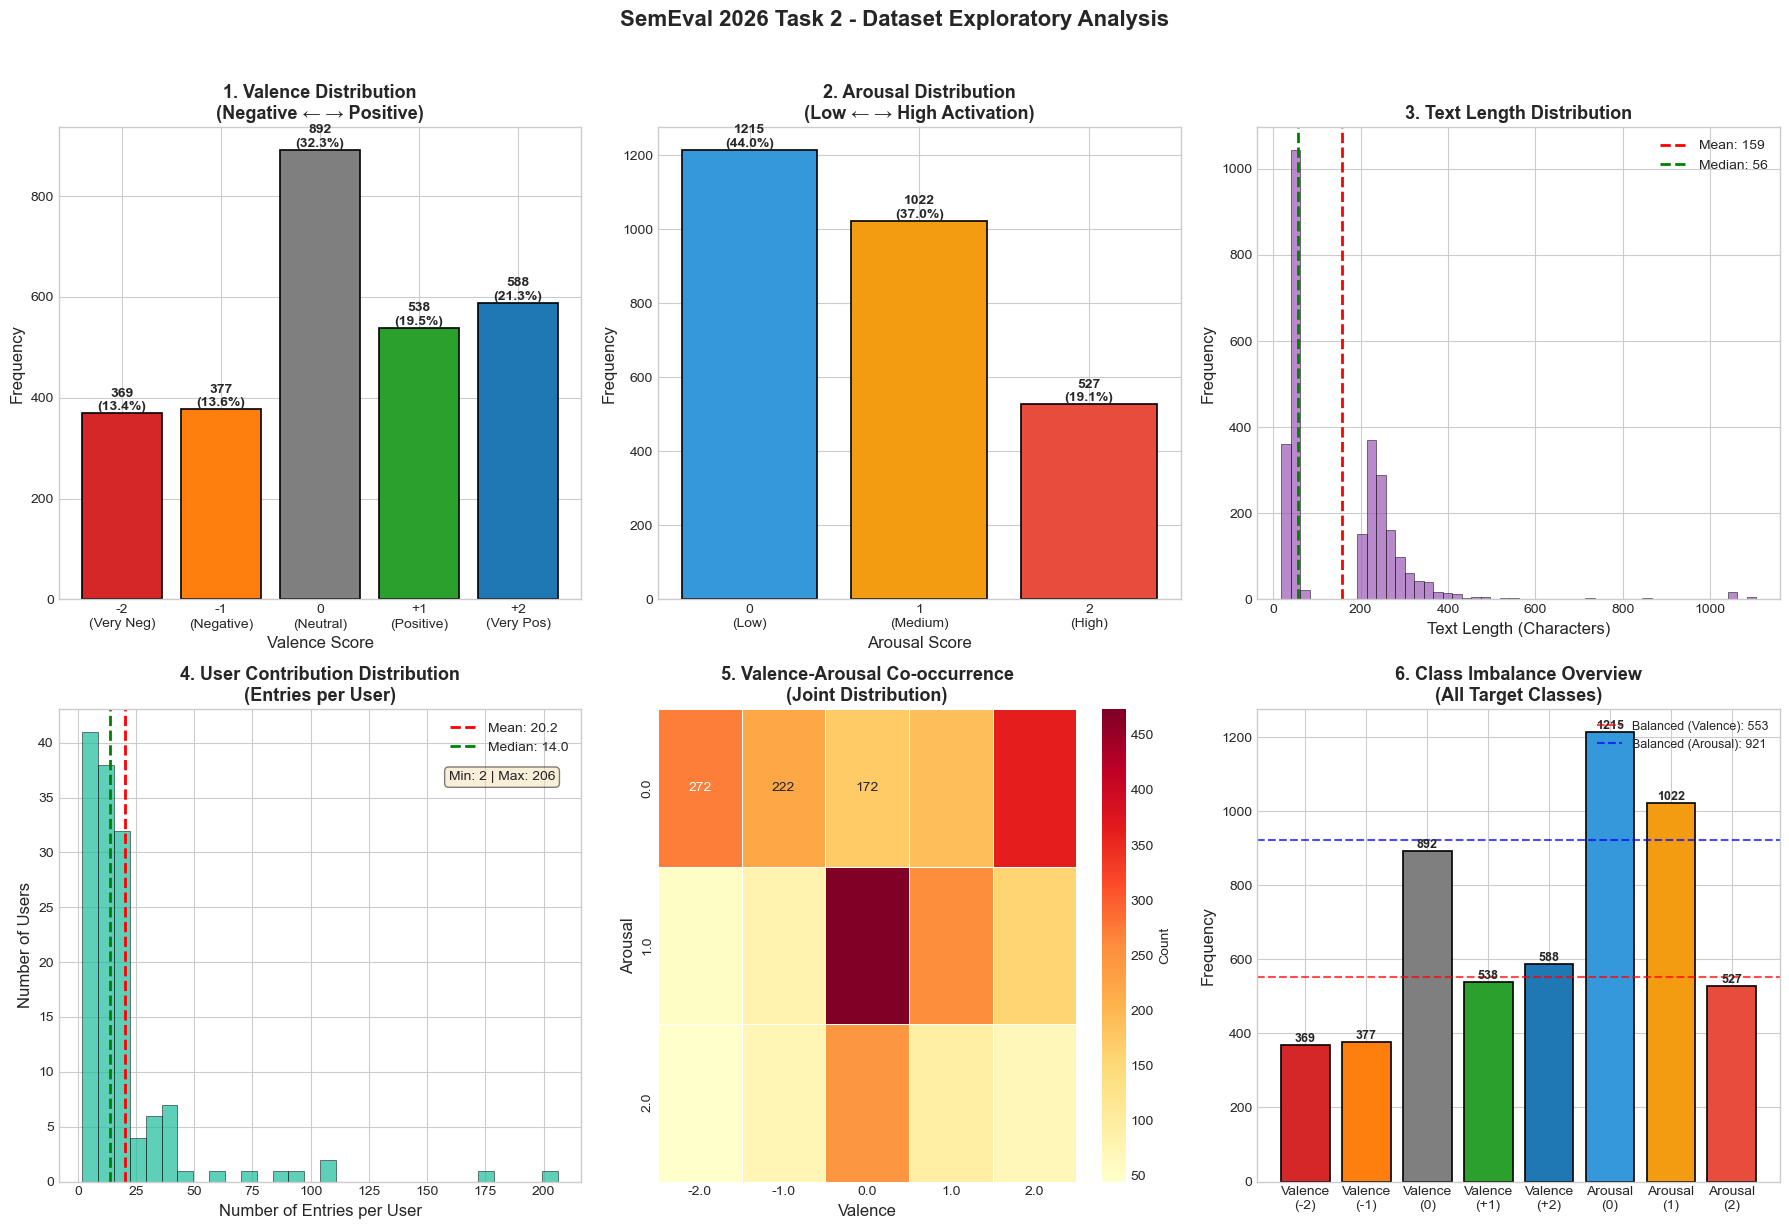


 Visualizations saved to 'eda_visualizations.png'


In [40]:
# =============================================================================
# EDA VISUALIZATIONS
# =============================================================================
# Creating 6 comprehensive visualizations to understand the dataset
# =============================================================================

# Create a large figure with 6 subplots (2 rows × 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('SemEval 2026 Task 2 - Dataset Exploratory Analysis', fontsize=16, fontweight='bold', y=1.02)

# -----------------------------------------------------------------------------
# PLOT 1: Valence Distribution (Top-Left)
# -----------------------------------------------------------------------------
ax1 = axes[0, 0]
valence_counts = df['valence'].value_counts().sort_index()
colors_valence = ['#d62728', '#ff7f0e', '#7f7f7f', '#2ca02c', '#1f77b4']  # Red to Blue gradient
bars1 = ax1.bar(valence_counts.index, valence_counts.values, color=colors_valence, edgecolor='black', linewidth=1.2)

# Add value labels on bars
for bar, count in zip(bars1, valence_counts.values):
    height = bar.get_height()
    ax1.annotate(f'{count}\n({count/len(df)*100:.1f}%)',
                xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_xlabel('Valence Score', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('1. Valence Distribution\n(Negative ← → Positive)', fontsize=13, fontweight='bold')
ax1.set_xticks([-2, -1, 0, 1, 2])
ax1.set_xticklabels(['-2\n(Very Neg)', '-1\n(Negative)', '0\n(Neutral)', '+1\n(Positive)', '+2\n(Very Pos)'])

# -----------------------------------------------------------------------------
# PLOT 2: Arousal Distribution (Top-Middle)
# -----------------------------------------------------------------------------
ax2 = axes[0, 1]
arousal_counts = df['arousal'].value_counts().sort_index()
colors_arousal = ['#3498db', '#f39c12', '#e74c3c']  # Low to High activation
bars2 = ax2.bar(arousal_counts.index, arousal_counts.values, color=colors_arousal, edgecolor='black', linewidth=1.2)

# Add value labels on bars
for bar, count in zip(bars2, arousal_counts.values):
    height = bar.get_height()
    ax2.annotate(f'{count}\n({count/len(df)*100:.1f}%)',
                xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.set_xlabel('Arousal Score', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)
ax2.set_title('2. Arousal Distribution\n(Low ← → High Activation)', fontsize=13, fontweight='bold')
ax2.set_xticks([0, 1, 2])
ax2.set_xticklabels(['0\n(Low)', '1\n(Medium)', '2\n(High)'])

# -----------------------------------------------------------------------------
# PLOT 3: Text Length Distribution (Top-Right)
# -----------------------------------------------------------------------------
ax3 = axes[0, 2]

# Histogram with KDE
ax3.hist(df['text_length'], bins=50, color='#9b59b6', alpha=0.7, edgecolor='black', linewidth=0.5)
ax3.axvline(df['text_length'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["text_length"].mean():.0f}')
ax3.axvline(df['text_length'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df["text_length"].median():.0f}')

ax3.set_xlabel('Text Length (Characters)', fontsize=12)
ax3.set_ylabel('Frequency', fontsize=12)
ax3.set_title('3. Text Length Distribution', fontsize=13, fontweight='bold')
ax3.legend(loc='upper right', fontsize=10)

# -----------------------------------------------------------------------------
# PLOT 4: Entries per User Distribution (Bottom-Left)
# -----------------------------------------------------------------------------
ax4 = axes[1, 0]
entries_per_user = df.groupby('user_id').size().sort_values(ascending=False)

ax4.hist(entries_per_user.values, bins=30, color='#1abc9c', alpha=0.7, edgecolor='black', linewidth=0.5)
ax4.axvline(entries_per_user.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {entries_per_user.mean():.1f}')
ax4.axvline(entries_per_user.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {entries_per_user.median():.1f}')

ax4.set_xlabel('Number of Entries per User', fontsize=12)
ax4.set_ylabel('Number of Users', fontsize=12)
ax4.set_title('4. User Contribution Distribution\n(Entries per User)', fontsize=13, fontweight='bold')
ax4.legend(loc='upper right', fontsize=10)

# Add annotation for imbalance
ax4.annotate(f'Min: {entries_per_user.min()} | Max: {entries_per_user.max()}',
            xy=(0.95, 0.85), xycoords='axes fraction',
            ha='right', fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# -----------------------------------------------------------------------------
# PLOT 5: Valence-Arousal Heatmap (Bottom-Middle)
# -----------------------------------------------------------------------------
ax5 = axes[1, 1]

# Create a cross-tabulation of valence and arousal
va_crosstab = pd.crosstab(df['arousal'], df['valence'])

# Plot heatmap
sns.heatmap(va_crosstab, annot=True, fmt='d', cmap='YlOrRd', ax=ax5, 
            cbar_kws={'label': 'Count'}, linewidths=0.5, linecolor='white')

ax5.set_xlabel('Valence', fontsize=12)
ax5.set_ylabel('Arousal', fontsize=12)
ax5.set_title('5. Valence-Arousal Co-occurrence\n(Joint Distribution)', fontsize=13, fontweight='bold')

# -----------------------------------------------------------------------------
# PLOT 6: Class Imbalance Summary (Bottom-Right)
# -----------------------------------------------------------------------------
ax6 = axes[1, 2]

# Prepare data for grouped bar chart
categories = ['Valence\n(-2)', 'Valence\n(-1)', 'Valence\n(0)', 'Valence\n(+1)', 'Valence\n(+2)', 
              'Arousal\n(0)', 'Arousal\n(1)', 'Arousal\n(2)']
counts = list(valence_counts.values) + list(arousal_counts.values)
colors_combined = colors_valence + colors_arousal

bars6 = ax6.bar(categories, counts, color=colors_combined, edgecolor='black', linewidth=1.2)

# Add horizontal line for balanced distribution
balanced_valence = len(df) / 5  # 5 valence classes
balanced_arousal = len(df) / 3  # 3 arousal classes
ax6.axhline(balanced_valence, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label=f'Balanced (Valence): {balanced_valence:.0f}')
ax6.axhline(balanced_arousal, color='blue', linestyle='--', linewidth=1.5, alpha=0.7, label=f'Balanced (Arousal): {balanced_arousal:.0f}')

# Add value labels
for bar, count in zip(bars6, counts):
    height = bar.get_height()
    ax6.annotate(f'{count}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax6.set_ylabel('Frequency', fontsize=12)
ax6.set_title('6. Class Imbalance Overview\n(All Target Classes)', fontsize=13, fontweight='bold')
ax6.legend(loc='upper right', fontsize=9)
ax6.tick_params(axis='x', rotation=0)

# Adjust layout and display
plt.tight_layout()
plt.savefig('eda_visualizations.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("\n Visualizations saved to 'eda_visualizations.png'")
print("=" * 60)

## EDA Key Findings

### Dataset overview

The data comes from ecological momentary assessments, in which users repeatedly wrote about how they were feeling.

| Metric | Value |
|--------|-------|
| Total samples | 2,764 text entries |
| Unique users | 137 |
| Entries per user | Min: 2, Max: 206, Mean: 20.18, Median: 14 |
| Missing values | None in any column |

The number of entries varies widely between users: some wrote only 2 entries, others more than 200.

### Target variable distributions

**Valence (5 classes: −2 to +2)** measures how positive or negative the writer feels. Neutral (0) is the most common class.

| Class | Count | Percentage |
|-------|-------|------------|
| -2 (Very Negative) | 369 | 13.4% |
| -1 (Negative) | 377 | 13.6% |
| 0 (Neutral) | 892 | **32.3%** (most frequent) |
| +1 (Positive) | 538 | 19.5% |
| +2 (Very Positive) | 588 | 21.3% |

**Arousal (3 classes: 0, 1, 2)** measures activation, i.e. how energetic or calm the writer feels. Low arousal is far more common than high arousal.

| Class | Count | Percentage |
|-------|-------|------------|
| 0 (Low) | 1,215 | **44.0%** (most frequent) |
| 1 (Medium) | 1,022 | 37.0% |
| 2 (High) | 527 | 19.1% (least frequent) |

### Text characteristics

Text lengths vary widely, from a few words to long essays.

| Metric | Characters | Words |
|--------|------------|-------|
| Minimum | 18 | 5 |
| Maximum | 1,105 | 225 |
| Mean | 158.6 | 32.9 |
| Median | 56 | 11 |

**Entry types:** 51.8% of entries are lists of single feeling words and 48.2% are full essays, as indicated by the `is_words` column.

### Implications for modeling

1. **Class imbalance:** neutral valence (32.3%) and low arousal (44.0%) dominate the dataset, which motivates a weighted loss function.

2. **User variability:** users contributed between 2 and 206 entries, so the data must be split by user to prevent information from leaking from training to validation.

3. **Arousal is expected to be harder:** its classes are strongly imbalanced, with almost half of the samples in class 0.

4. **Extreme values are rare:** valence −2/+2 and arousal 2 are under-represented, so the model is likely to struggle with them.

5. **Skewed text lengths:** the gap between the median (56 characters) and the mean (158 characters) shows a right-skewed distribution, with many short texts and a few very long ones.

# Baseline Model: DistilBERT Regression

The baseline fine-tunes DistilBERT, a smaller and faster distilled version of BERT that keeps most of its accuracy. Each text is encoded by DistilBERT, and a regression head predicts valence and arousal jointly.

## Why this approach

- Pre-trained transformers are a strong starting point for text understanding
- DistilBERT is small enough to fine-tune on modest hardware
- It provides a reference point for the more complex sequence models that follow

## Model architecture

1. **DistilBERT encoder:** produces contextual embeddings for the tokenized text (max. 128 tokens)
2. **Dropout (p = 0.3)** to reduce overfitting
3. **Linear regression head:** maps the [CLS] embedding to 2 outputs (valence and arousal)

## Training setup

- User-based split: 80% of users for training, 20% for validation (no user appears in both)
- Inverse-frequency weighted MSE loss (see the next section)
- AdamW optimizer, learning rate 2e-5, batch size 16, 5 epochs, linear learning-rate schedule
- The checkpoint with the lowest validation loss is saved

# Weighted Loss for Class Imbalance

The EDA showed significant class imbalance:
- **Valence:** neutral (0) makes up 32.3% of the data, while the extreme values (−2, +2) are less common
- **Arousal:** low arousal (0) makes up 44% of the data, high arousal (2) only 19%

## Why a weighted loss

Standard MSE treats every sample equally, so:
- the model optimizes mostly for the frequent classes (neutral valence, low arousal)
- rare classes (extreme emotions) get less attention during training
- performance on minority classes suffers

## Method

**Inverse-frequency weighting** for regression:
1. Round the targets to their discrete classes
2. Count the frequency of each class
3. Set each class weight to the inverse of its frequency (with smoothing), normalized to a mean of 1
4. Multiply each sample's squared error by the weight of its target class

This gives under-represented emotional states more influence during training.

In [41]:
# =============================================================================
# WEIGHTED LOSS IMPLEMENTATION FOR CLASS IMBALANCE
# =============================================================================
# This module implements inverse frequency weighting for regression tasks
# to handle the imbalanced distribution of valence and arousal values.
# =============================================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# -----------------------------------------------------------------------------
# COMPUTE CLASS WEIGHTS FROM TRAINING DATA
# -----------------------------------------------------------------------------
def compute_class_weights(df, smooth=1.0):
    """
    Compute inverse frequency weights for valence and arousal.
    
    Args:
        df: DataFrame with 'valence' and 'arousal' columns
        smooth: Smoothing factor to prevent extreme weights
    
    Returns:
        valence_weights: dict mapping valence values to weights
        arousal_weights: dict mapping arousal values to weights
    """
    # Valence weights (classes: -2, -1, 0, 1, 2)
    valence_counts = df['valence'].value_counts()
    total_valence = len(df)
    n_valence_classes = len(valence_counts)
    
    valence_weights = {}
    for val in [-2, -1, 0, 1, 2]:
        count = valence_counts.get(val, 1)
        # Inverse frequency with smoothing
        weight = total_valence / (n_valence_classes * count + smooth)
        valence_weights[val] = weight
    
    # Normalize weights so mean = 1
    mean_weight = sum(valence_weights.values()) / len(valence_weights)
    valence_weights = {k: v / mean_weight for k, v in valence_weights.items()}
    
    # Arousal weights (classes: 0, 1, 2)
    arousal_counts = df['arousal'].value_counts()
    total_arousal = len(df)
    n_arousal_classes = len(arousal_counts)
    
    arousal_weights = {}
    for val in [0, 1, 2]:
        count = arousal_counts.get(val, 1)
        weight = total_arousal / (n_arousal_classes * count + smooth)
        arousal_weights[val] = weight
    
    mean_weight = sum(arousal_weights.values()) / len(arousal_weights)
    arousal_weights = {k: v / mean_weight for k, v in arousal_weights.items()}
    
    return valence_weights, arousal_weights

# -----------------------------------------------------------------------------
# WEIGHTED MSE LOSS CLASS
# -----------------------------------------------------------------------------
class WeightedMSELoss(nn.Module):
    """
    Weighted MSE Loss that applies different weights based on target values.
    Useful for handling class imbalance in regression tasks.
    """
    def __init__(self, valence_weights, arousal_weights, device='cpu'):
        super(WeightedMSELoss, self).__init__()
        self.valence_weights = valence_weights
        self.arousal_weights = arousal_weights
        self.device = device
        self.mse = nn.MSELoss(reduction='none')
    
    def forward(self, predictions, targets):
        """
        Compute weighted MSE loss.
        
        Args:
            predictions: (batch_size, 2) - predicted [valence, arousal]
            targets: (batch_size, 2) - ground truth [valence, arousal]
        
        Returns:
            Weighted MSE loss (scalar)
        """
        # Compute per-sample MSE
        mse_loss = self.mse(predictions, targets)  # (batch_size, 2)
        
        # Get weight for each sample based on its target class
        batch_size = targets.shape[0]
        weights = torch.ones(batch_size, 2, device=self.device)
        
        # Discretize targets to get weights (round to nearest integer)
        valence_classes = torch.clamp(torch.round(targets[:, 0]), -2, 2).long()
        arousal_classes = torch.clamp(torch.round(targets[:, 1]), 0, 2).long()
        
        # Apply weights
        for i in range(batch_size):
            v_class = valence_classes[i].item()
            a_class = arousal_classes[i].item()
            weights[i, 0] = self.valence_weights.get(v_class, 1.0)
            weights[i, 1] = self.arousal_weights.get(a_class, 1.0)
        
        # Weighted MSE
        weighted_loss = (mse_loss * weights).mean()
        
        return weighted_loss

# -----------------------------------------------------------------------------
# FASTER VECTORIZED WEIGHTED LOSS (For larger batches)
# -----------------------------------------------------------------------------
class WeightedMSELossFast(nn.Module):
    """
    Optimized version using vectorized operations.
    Pre-computes weight tensors for faster forward pass.
    """
    def __init__(self, valence_weights, arousal_weights, device='cpu'):
        super(WeightedMSELossFast, self).__init__()
        
        # Create weight lookup tensors
        # Valence: indices 0-4 correspond to values -2 to +2
        self.valence_weight_tensor = torch.tensor(
            [valence_weights.get(i-2, 1.0) for i in range(5)],
            dtype=torch.float32, device=device
        )
        
        # Arousal: indices 0-2 correspond to values 0 to 2
        self.arousal_weight_tensor = torch.tensor(
            [arousal_weights.get(i, 1.0) for i in range(3)],
            dtype=torch.float32, device=device
        )
        
        self.device = device
    
    def forward(self, predictions, targets):
        # Per-sample squared error
        se = (predictions - targets) ** 2  # (batch_size, 2)
        
        # Get class indices for weight lookup
        valence_idx = torch.clamp(torch.round(targets[:, 0]).long() + 2, 0, 4)  # Map -2..+2 to 0..4
        arousal_idx = torch.clamp(torch.round(targets[:, 1]).long(), 0, 2)
        
        # Lookup weights
        valence_weights = self.valence_weight_tensor[valence_idx]
        arousal_weights = self.arousal_weight_tensor[arousal_idx]
        
        # Stack weights
        weights = torch.stack([valence_weights, arousal_weights], dim=1)
        
        # Weighted mean
        weighted_loss = (se * weights).mean()
        
        return weighted_loss

# -----------------------------------------------------------------------------
# DEMONSTRATION: Compute and Display Weights
# -----------------------------------------------------------------------------
def display_class_weights():
    """Load data and show computed weights."""
    print("=" * 60)
    print("CLASS IMBALANCE WEIGHTS")
    print("=" * 60)
    
    # Load data
    df = pd.read_csv('train_subtask1.csv')
    valence_weights, arousal_weights = compute_class_weights(df)
    
    print("\n VALENCE WEIGHTS (Inverse Frequency):")
    print("-" * 40)
    valence_counts = df['valence'].value_counts().sort_index()
    for val in [-2, -1, 0, 1, 2]:
        count = valence_counts.get(val, 0)
        weight = valence_weights[val]
        pct = count / len(df) * 100
        bar = "█" * int(weight * 10)
        print(f"   Class {val:+d}: Count={count:4d} ({pct:5.1f}%) | Weight={weight:.3f} {bar}")
    
    print("\n AROUSAL WEIGHTS (Inverse Frequency):")
    print("-" * 40)
    arousal_counts = df['arousal'].value_counts().sort_index()
    for val in [0, 1, 2]:
        count = arousal_counts.get(val, 0)
        weight = arousal_weights[val]
        pct = count / len(df) * 100
        bar = "█" * int(weight * 10)
        print(f"   Class {val}: Count={count:4d} ({pct:5.1f}%) | Weight={weight:.3f} {bar}")
    
    print("\nInterpretation:")
    print("   - Weights > 1.0: Underrepresented classes (model will pay more attention)")
    print("   - Weights < 1.0: Overrepresented classes (model will pay less attention)")
    print("   - This balances the learning across all emotional states")
    
    print("\n" + "=" * 60)
    print("Weights computed successfully!")
    print("=" * 60)
    
    return valence_weights, arousal_weights

# Run the demonstration
if __name__ == "__main__":
    valence_weights, arousal_weights = display_class_weights()

CLASS IMBALANCE WEIGHTS

 VALENCE WEIGHTS (Inverse Frequency):
----------------------------------------
   Class -2: Count= 369 ( 13.4%) | Weight=1.349 █████████████
   Class -1: Count= 377 ( 13.6%) | Weight=1.320 █████████████
   Class +0: Count= 892 ( 32.3%) | Weight=0.558 █████
   Class +1: Count= 538 ( 19.5%) | Weight=0.925 █████████
   Class +2: Count= 588 ( 21.3%) | Weight=0.847 ████████

 AROUSAL WEIGHTS (Inverse Frequency):
----------------------------------------
   Class 0: Count=1215 ( 44.0%) | Weight=0.668 ██████
   Class 1: Count=1022 ( 37.0%) | Weight=0.794 ███████
   Class 2: Count= 527 ( 19.1%) | Weight=1.539 ███████████████

Interpretation:
   - Weights > 1.0: Underrepresented classes (model will pay more attention)
   - Weights < 1.0: Overrepresented classes (model will pay less attention)
   - This balances the learning across all emotional states

Weights computed successfully!


In [43]:
# --- LOADING REQUIRED LIBRARIES ---

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
# FIX HERE: AdamW is now imported from torch.optim
from torch.optim import AdamW
# get_linear_schedule_with_warmup is still inside transformers
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

# --- 1. CONFIGURATION SETTINGS ---
class Config:
    CSV_PATH = 'train_subtask1.csv'
    MODEL_NAME = 'distilbert-base-uncased'
    MAX_LEN = 128
    TRAIN_BATCH_SIZE = 16
    VALID_BATCH_SIZE = 32
    EPOCHS = 5
    LEARNING_RATE = 2e-5
    NUM_LABELS = 2         # Valence, Arousal
    SEED = 42
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

config = Config()

# --- 2. REPRODUCIBILITY (SEED EVERYTHING) ---
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(config.SEED)

# --- 3. DATASET CLASS ---
class EcologicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len):
        self.data = dataframe
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.text = dataframe.text.values
        self.targets = dataframe[['valence', 'arousal']].values

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        text = str(self.text[index])
        targets = self.targets[index]

        inputs = self.tokenizer.encode_plus(
            text,
            None,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_token_type_ids=False,
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'input_ids': inputs['input_ids'].flatten(),
            'attention_mask': inputs['attention_mask'].flatten(),
            'targets': torch.tensor(targets, dtype=torch.float)
        }

# --- 4. MODEL CLASS (MODULAR DESIGN) ---
class SentimentRegressor(nn.Module):
    def __init__(self, model_name, num_labels=2):
        super(SentimentRegressor, self).__init__()
        self.bert = AutoModel.from_pretrained(model_name)

        # We can add LSTM here in the future

        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        pooled_output = outputs.last_hidden_state[:, 0, :]
        output = self.drop(pooled_output)
        return self.out(output)

# --- 5. HELPER FUNCTIONS ---
def user_based_split(df, test_size=0.2, seed=42):
    unique_users = df['user_id'].unique()
    np.random.seed(seed)
    np.random.shuffle(unique_users)

    split_idx = int(len(unique_users) * (1 - test_size))
    train_users = unique_users[:split_idx]
    val_users = unique_users[split_idx:]

    train_df = df[df['user_id'].isin(train_users)].reset_index(drop=True)
    val_df = df[df['user_id'].isin(val_users)].reset_index(drop=True)

    return train_df, val_df

# --- WEIGHTED LOSS FUNCTION FOR CLASS IMBALANCE ---
def compute_weights_for_baseline(df):
    """Compute inverse frequency weights for valence and arousal."""
    # Valence weights
    valence_counts = df['valence'].value_counts()
    total = len(df)
    valence_weights = {}
    for val in [-2, -1, 0, 1, 2]:
        count = valence_counts.get(val, 1)
        valence_weights[val] = total / (5 * count + 1)
    mean_w = sum(valence_weights.values()) / 5
    valence_weights = {k: v / mean_w for k, v in valence_weights.items()}
    
    # Arousal weights
    arousal_counts = df['arousal'].value_counts()
    arousal_weights = {}
    for val in [0, 1, 2]:
        count = arousal_counts.get(val, 1)
        arousal_weights[val] = total / (3 * count + 1)
    mean_w = sum(arousal_weights.values()) / 3
    arousal_weights = {k: v / mean_w for k, v in arousal_weights.items()}
    
    return valence_weights, arousal_weights

class WeightedMSELossBaseline(nn.Module):
    """Weighted MSE Loss for handling class imbalance in regression."""
    def __init__(self, valence_weights, arousal_weights, device):
        super().__init__()
        # Create lookup tensors
        self.valence_w = torch.tensor(
            [valence_weights.get(i-2, 1.0) for i in range(5)],
            dtype=torch.float32, device=device
        )
        self.arousal_w = torch.tensor(
            [arousal_weights.get(i, 1.0) for i in range(3)],
            dtype=torch.float32, device=device
        )
    
    def forward(self, predictions, targets):
        se = (predictions - targets) ** 2
        v_idx = torch.clamp(torch.round(targets[:, 0]).long() + 2, 0, 4)
        a_idx = torch.clamp(torch.round(targets[:, 1]).long(), 0, 2)
        weights = torch.stack([self.valence_w[v_idx], self.arousal_w[a_idx]], dim=1)
        return (se * weights).mean()

# Global variable to store the weighted loss function
weighted_loss_fn = None

def loss_fn(outputs, targets):
    """Use weighted loss if available, otherwise standard MSE."""
    global weighted_loss_fn
    if weighted_loss_fn is not None:
        return weighted_loss_fn(outputs, targets)
    return nn.MSELoss()(outputs, targets)

# --- 6. TRAINING AND EVALUATION LOOPS ---
def train_fn(data_loader, model, optimizer, device, scheduler):
    model.train()
    final_loss = 0
    progress_bar = tqdm(data_loader, total=len(data_loader), desc="Training")

    for data in progress_bar:
        input_ids = data['input_ids'].to(device)
        attention_mask = data['attention_mask'].to(device)
        targets = data['targets'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = loss_fn(outputs, targets)
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        final_loss += loss.item()
        progress_bar.set_postfix({'loss': loss.item()})

    return final_loss / len(data_loader)

def eval_fn(data_loader, model, device):
    model.eval()
    final_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for data in data_loader:
            input_ids = data['input_ids'].to(device)
            attention_mask = data['attention_mask'].to(device)
            targets = data['targets'].to(device)

            outputs = model(input_ids, attention_mask)
            loss = loss_fn(outputs, targets)
            final_loss += loss.item()

            all_preds.extend(outputs.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    return final_loss / len(data_loader), np.array(all_preds), np.array(all_targets)

# --- 7. MAIN EXECUTION BLOCK ---
def run():
    global weighted_loss_fn
    
    print("Loading data...")
    # Make sure the file name is correct
    if not os.path.exists(config.CSV_PATH):
        print(f"ERROR: {config.CSV_PATH} was not found! Please check file name or path.")
        return None, None, None

    df = pd.read_csv(config.CSV_PATH)

    train_df, val_df = user_based_split(df, test_size=0.2, seed=config.SEED)
    print(f"Training Set: {len(train_df)} samples ({train_df['user_id'].nunique()} users)")
    print(f"Validation Set: {len(val_df)} samples ({val_df['user_id'].nunique()} users)")

    # Compute class weights from training data for weighted loss
    print("\nComputing class weights for imbalanced data...")
    valence_weights, arousal_weights = compute_weights_for_baseline(train_df)
    weighted_loss_fn = WeightedMSELossBaseline(valence_weights, arousal_weights, config.DEVICE)
    print("Weighted loss function initialized!")
    print(f"   Valence weights: {valence_weights}")
    print(f"   Arousal weights: {arousal_weights}")

    tokenizer = AutoTokenizer.from_pretrained(config.MODEL_NAME)

    train_dataset = EcologicalDataset(train_df, tokenizer, config.MAX_LEN)
    train_loader = DataLoader(train_dataset, batch_size=config.TRAIN_BATCH_SIZE, shuffle=True)

    val_dataset = EcologicalDataset(val_df, tokenizer, config.MAX_LEN)
    val_loader = DataLoader(val_dataset, batch_size=config.VALID_BATCH_SIZE, shuffle=False)

    model = SentimentRegressor(config.MODEL_NAME, config.NUM_LABELS)
    model.to(config.DEVICE)

    # FIX HERE: We use PyTorch AdamW, the correct_bias parameter was removed.
    optimizer = AdamW(model.parameters(), lr=config.LEARNING_RATE)

    num_train_steps = int(len(train_df) / config.TRAIN_BATCH_SIZE * config.EPOCHS)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=0, num_training_steps=num_train_steps
    )

    best_val_loss = float('inf')

    print(f"\nTraining is starting ({config.EPOCHS} epochs)...")
    for epoch in range(config.EPOCHS):
        train_loss = train_fn(train_loader, model, optimizer, config.DEVICE, scheduler)
        val_loss, preds, targets = eval_fn(val_loader, model, config.DEVICE)

        # Calculate Pearson Correlation
        val_corr_valence, _ = pearsonr(targets[:, 0], preds[:, 0])
        val_corr_arousal, _ = pearsonr(targets[:, 1], preds[:, 1])
        avg_corr = (val_corr_valence + val_corr_arousal) / 2

        print(f"\nEpoch {epoch+1}/{config.EPOCHS}")
        print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        print(f"Valence Corr: {val_corr_valence:.4f} | Arousal Corr: {val_corr_arousal:.4f} | Avg Corr: {avg_corr:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # Save the best model
            torch.save(model.state_dict(), "best_baseline_model.bin")
            print("-> Best model is saved!")

    return model, preds, targets

if __name__ == "__main__":
    model, preds, targets = run()

Loading data...
Training Set: 2192 samples (109 users)
Validation Set: 572 samples (28 users)

Computing class weights for imbalanced data...
Weighted loss function initialized!
   Valence weights: {-2: 1.3690157791291158, -1: 1.3690157791291158, 0: 0.4839214154228397, 1: 0.9139960837538317, 2: 0.8640509425650976}
   Arousal weights: {0: 0.6922358030592526, 1: 0.7445965406839827, 2: 1.563167656256765}

Training is starting (5 epochs)...

Epoch 1/5
Train Loss: 0.7996 | Val Loss: 0.6391
Valence Corr: 0.7876 | Arousal Corr: 0.5633 | Avg Corr: 0.6755
-> Best model is saved!

Epoch 2/5
Train Loss: 0.5598 | Val Loss: 0.6247
Valence Corr: 0.7797 | Arousal Corr: 0.5630 | Avg Corr: 0.6714
-> Best model is saved!

Epoch 3/5
Train Loss: 0.4642 | Val Loss: 0.6533
Valence Corr: 0.7683 | Arousal Corr: 0.5419 | Avg Corr: 0.6551

Epoch 4/5
Train Loss: 0.3931 | Val Loss: 0.6517
Valence Corr: 0.7664 | Arousal Corr: 0.5435 | Avg Corr: 0.6549

Epoch 5/5
Train Loss: 0.3480 | Val Loss: 0.6634
Valence Corr: 

# K-Fold Cross-Validation

A single train/validation split can give an unstable performance estimate, so the baseline is also evaluated with **user-based K-fold cross-validation**.

## Why user-based folds

- **Standard K-fold** splits samples at random and can put the same user's entries in both training and validation (data leakage)
- **User-based K-fold** assigns each user to exactly one fold, which gives a realistic estimate of performance on new users

## Setup

1. Split the 137 users into K = 5 folds
2. For each fold, train on the other 4 folds and validate on the held-out fold (3 epochs per fold, weighted loss)
3. Report the mean, standard deviation and 95% interval of each metric across folds

USER-BASED K-FOLD CROSS-VALIDATION

Configuration:
   K Folds: 5
   Epochs per fold: 3
   Model: distilbert-base-uncased
   Device: cpu
   Using: Weighted Loss for Class Imbalance

Dataset:
   Total samples: 2764
   Total users: 137
   Users per fold: ~27

Starting Cross-Validation...


FOLD 1/5
----------------------------------------
   Train: 2357 samples (109 users)
   Val:   407 samples (28 users)
   Weighted loss initialized for fold
   Epoch 1: Train Loss=0.8139 | Val Corr: V=0.653, A=0.357, Avg=0.505
   Epoch 2: Train Loss=0.5464 | Val Corr: V=0.669, A=0.417, Avg=0.543
   Epoch 3: Train Loss=0.4595 | Val Corr: V=0.671, A=0.421, Avg=0.546
   Best Avg Correlation: 0.5457

FOLD 2/5
----------------------------------------
   Train: 2004 samples (109 users)
   Val:   760 samples (28 users)
   Weighted loss initialized for fold
   Epoch 1: Train Loss=0.8483 | Val Corr: V=0.644, A=0.492, Avg=0.568
   Epoch 2: Train Loss=0.6011 | Val Corr: V=0.634, A=0.487, Avg=0.560
   Epoch 3: Train

,fold,valence_corr,arousal_corr,avg_corr,val_loss
0,1,0.6707,0.4207,0.5457,0.7085
1,2,0.6443,0.4925,0.5684,0.5846
2,3,0.6442,0.3897,0.5169,0.7469
3,4,0.6520,0.4596,0.5558,0.6510
4,5,0.7845,0.5503,0.6674,0.6683



Aggregated Statistics:
------------------------------------------------------------

Valence Correlation:
   Mean +/- Std: 0.6791 +/- 0.0599
   Range: [0.6442, 0.7845]
   95% CI: [0.5618, 0.7965]

Arousal Correlation:
   Mean +/- Std: 0.4626 +/- 0.0626
   Range: [0.3897, 0.5503]
   95% CI: [0.3399, 0.5852]

Average Correlation:
   Mean +/- Std: 0.5708 +/- 0.0572
   Range: [0.5169, 0.6674]
   95% CI: [0.4587, 0.6830]


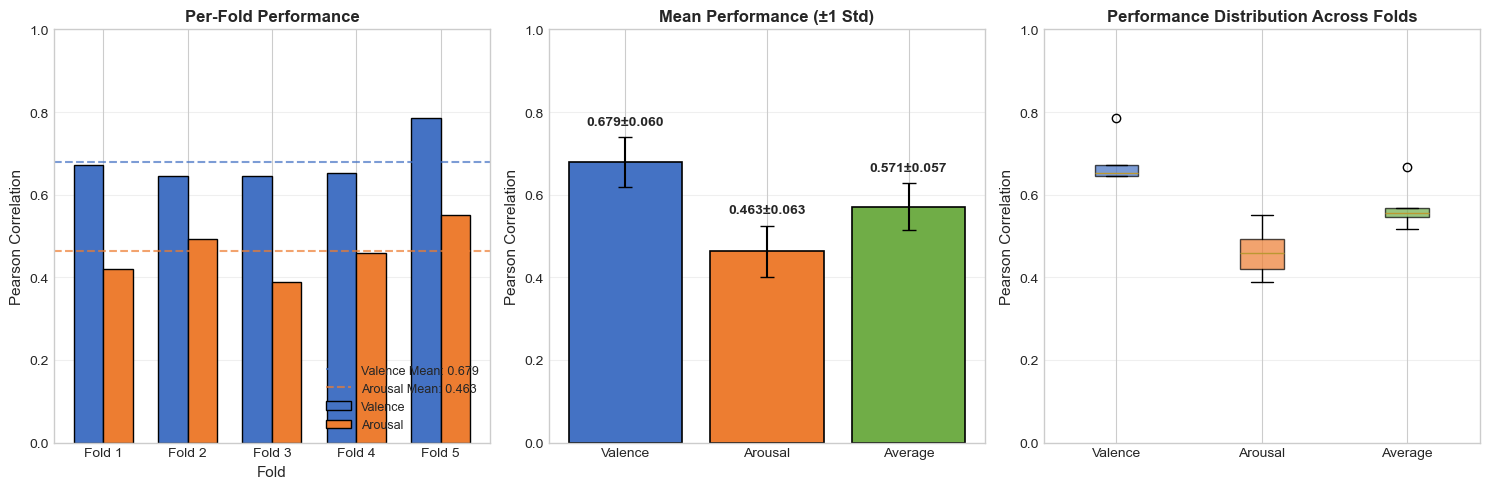


CROSS-VALIDATION SUMMARY

Final Performance Estimate (5-Fold CV):
   Valence Correlation: 0.6791 +/- 0.0599
   Arousal Correlation: 0.4626 +/- 0.0626
   Average Correlation: 0.5708 +/- 0.0572

Interpretation:
   Moderate variance - some sensitivity to user composition

Cross-Validation Complete!


In [44]:
# =============================================================================
# USER-BASED K-FOLD CROSS-VALIDATION WITH WEIGHTED LOSS
# =============================================================================
# This implementation performs K-Fold CV at the user level to prevent data
# leakage and get robust performance estimates with confidence intervals.
# Now includes weighted loss for class imbalance!
# =============================================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import KFold
from scipy.stats import pearsonr
from tqdm import tqdm
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# -----------------------------------------------------------------------------
# CONFIGURATION FOR CROSS-VALIDATION
# -----------------------------------------------------------------------------
class CVConfig:
    CSV_PATH = 'train_subtask1.csv'
    MODEL_NAME = 'distilbert-base-uncased'
    MAX_LEN = 128
    TRAIN_BATCH_SIZE = 16
    VALID_BATCH_SIZE = 32
    EPOCHS = 3  # Reduced epochs for CV (faster iteration)
    LEARNING_RATE = 2e-5
    NUM_LABELS = 2
    SEED = 42
    N_FOLDS = 5  # Number of folds for cross-validation
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cv_config = CVConfig()

# -----------------------------------------------------------------------------
# SEED EVERYTHING FOR REPRODUCIBILITY
# -----------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(cv_config.SEED)

# -----------------------------------------------------------------------------
# DATASET CLASS
# -----------------------------------------------------------------------------
class EcologicalDatasetCV(Dataset):
    def __init__(self, dataframe, tokenizer, max_len):
        self.data = dataframe
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.text = dataframe.text.values
        self.targets = dataframe[['valence', 'arousal']].values

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        text = str(self.text[index])
        targets = self.targets[index]

        inputs = self.tokenizer.encode_plus(
            text, None, add_special_tokens=True, max_length=self.max_len,
            padding='max_length', truncation=True,
            return_token_type_ids=False, return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'input_ids': inputs['input_ids'].flatten(),
            'attention_mask': inputs['attention_mask'].flatten(),
            'targets': torch.tensor(targets, dtype=torch.float)
        }

# -----------------------------------------------------------------------------
# MODEL CLASS
# -----------------------------------------------------------------------------
class SentimentRegressorCV(nn.Module):
    def __init__(self, model_name, num_labels=2):
        super(SentimentRegressorCV, self).__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0, :]
        output = self.drop(pooled_output)
        return self.out(output)

# -----------------------------------------------------------------------------
# WEIGHTED LOSS FOR K-FOLD CV
# -----------------------------------------------------------------------------
class WeightedMSELossCV(nn.Module):
    """Weighted MSE Loss for handling class imbalance in K-Fold CV."""
    def __init__(self, valence_weights, arousal_weights, device):
        super().__init__()
        self.valence_w = torch.tensor(
            [valence_weights.get(i-2, 1.0) for i in range(5)],
            dtype=torch.float32, device=device
        )
        self.arousal_w = torch.tensor(
            [arousal_weights.get(i, 1.0) for i in range(3)],
            dtype=torch.float32, device=device
        )
    
    def forward(self, predictions, targets):
        se = (predictions - targets) ** 2
        v_idx = torch.clamp(torch.round(targets[:, 0]).long() + 2, 0, 4)
        a_idx = torch.clamp(torch.round(targets[:, 1]).long(), 0, 2)
        weights = torch.stack([self.valence_w[v_idx], self.arousal_w[a_idx]], dim=1)
        return (se * weights).mean()

def compute_weights_cv(df):
    """Compute class weights for weighted loss."""
    valence_counts = df['valence'].value_counts()
    arousal_counts = df['arousal'].value_counts()
    total = len(df)
    
    valence_weights = {}
    for val in [-2, -1, 0, 1, 2]:
        count = valence_counts.get(val, 1)
        valence_weights[val] = total / (5 * count + 1)
    mean_w = sum(valence_weights.values()) / 5
    valence_weights = {k: v / mean_w for k, v in valence_weights.items()}
    
    arousal_weights = {}
    for val in [0, 1, 2]:
        count = arousal_counts.get(val, 1)
        arousal_weights[val] = total / (3 * count + 1)
    mean_w = sum(arousal_weights.values()) / 3
    arousal_weights = {k: v / mean_w for k, v in arousal_weights.items()}
    
    return valence_weights, arousal_weights

# -----------------------------------------------------------------------------
# TRAINING AND EVALUATION FUNCTIONS
# -----------------------------------------------------------------------------
def train_one_epoch_cv(data_loader, model, optimizer, device, scheduler, weighted_loss_fn):
    model.train()
    total_loss = 0
    
    for data in data_loader:
        input_ids = data['input_ids'].to(device)
        attention_mask = data['attention_mask'].to(device)
        targets = data['targets'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = weighted_loss_fn(outputs, targets)
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(data_loader)

def evaluate_cv(data_loader, model, device, weighted_loss_fn):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for data in data_loader:
            input_ids = data['input_ids'].to(device)
            attention_mask = data['attention_mask'].to(device)
            targets = data['targets'].to(device)

            outputs = model(input_ids, attention_mask)
            loss = weighted_loss_fn(outputs, targets)
            total_loss += loss.item()

            all_preds.extend(outputs.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    preds = np.array(all_preds)
    targets = np.array(all_targets)
    
    valence_corr = pearsonr(targets[:, 0], preds[:, 0])[0]
    arousal_corr = pearsonr(targets[:, 1], preds[:, 1])[0]
    
    return {
        'loss': total_loss / len(data_loader),
        'valence_corr': valence_corr,
        'arousal_corr': arousal_corr,
        'avg_corr': (valence_corr + arousal_corr) / 2
    }

# -----------------------------------------------------------------------------
# MAIN CROSS-VALIDATION FUNCTION
# -----------------------------------------------------------------------------
def run_cross_validation():
    print("=" * 80)
    print("USER-BASED K-FOLD CROSS-VALIDATION")
    print("=" * 80)
    print(f"\nConfiguration:")
    print(f"   K Folds: {cv_config.N_FOLDS}")
    print(f"   Epochs per fold: {cv_config.EPOCHS}")
    print(f"   Model: {cv_config.MODEL_NAME}")
    print(f"   Device: {cv_config.DEVICE}")
    print(f"   Using: Weighted Loss for Class Imbalance")
    
    # Load data
    df = pd.read_csv(cv_config.CSV_PATH)
    unique_users = df['user_id'].unique()
    n_users = len(unique_users)

    print(f"\nDataset:")
    print(f"   Total samples: {len(df)}")
    print(f"   Total users: {n_users}")
    print(f"   Users per fold: ~{n_users // cv_config.N_FOLDS}")
    
    # Initialize tokenizer
    tokenizer = AutoTokenizer.from_pretrained(cv_config.MODEL_NAME)
    
    # User-based K-Fold
    kfold = KFold(n_splits=cv_config.N_FOLDS, shuffle=True, random_state=cv_config.SEED)
    
    # Store results for each fold
    fold_results = []
    
    print(f"\n{'='*80}")
    print("Starting Cross-Validation...")
    print(f"{'='*80}\n")
    
    for fold, (train_user_idx, val_user_idx) in enumerate(kfold.split(unique_users)):
        print(f"\nFOLD {fold + 1}/{cv_config.N_FOLDS}")
        print("-" * 40)
        
        # Get users for this fold
        train_users = unique_users[train_user_idx]
        val_users = unique_users[val_user_idx]
        
        # Split data by users
        train_df = df[df['user_id'].isin(train_users)].reset_index(drop=True)
        val_df = df[df['user_id'].isin(val_users)].reset_index(drop=True)
        
        print(f"   Train: {len(train_df)} samples ({len(train_users)} users)")
        print(f"   Val:   {len(val_df)} samples ({len(val_users)} users)")
        
        # Compute weighted loss for this fold's training data
        valence_weights, arousal_weights = compute_weights_cv(train_df)
        weighted_loss_fn = WeightedMSELossCV(valence_weights, arousal_weights, cv_config.DEVICE)
        print(f"   Weighted loss initialized for fold")
        
        # Create datasets and loaders
        train_dataset = EcologicalDatasetCV(train_df, tokenizer, cv_config.MAX_LEN)
        val_dataset = EcologicalDatasetCV(val_df, tokenizer, cv_config.MAX_LEN)
        
        train_loader = DataLoader(train_dataset, batch_size=cv_config.TRAIN_BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=cv_config.VALID_BATCH_SIZE, shuffle=False)
        
        # Initialize fresh model for each fold
        model = SentimentRegressorCV(cv_config.MODEL_NAME, cv_config.NUM_LABELS)
        model.to(cv_config.DEVICE)
        
        optimizer = AdamW(model.parameters(), lr=cv_config.LEARNING_RATE)
        num_train_steps = len(train_loader) * cv_config.EPOCHS
        scheduler = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=0, num_training_steps=num_train_steps
        )
        
        # Training loop for this fold
        best_val_corr = -1
        best_metrics = None
        
        for epoch in range(cv_config.EPOCHS):
            train_loss = train_one_epoch_cv(train_loader, model, optimizer, cv_config.DEVICE, scheduler, weighted_loss_fn)
            val_metrics = evaluate_cv(val_loader, model, cv_config.DEVICE, weighted_loss_fn)
            
            if val_metrics['avg_corr'] > best_val_corr:
                best_val_corr = val_metrics['avg_corr']
                best_metrics = val_metrics.copy()
            
            print(f"   Epoch {epoch+1}: Train Loss={train_loss:.4f} | "
                  f"Val Corr: V={val_metrics['valence_corr']:.3f}, A={val_metrics['arousal_corr']:.3f}, "
                  f"Avg={val_metrics['avg_corr']:.3f}")
        
        fold_results.append({
            'fold': fold + 1,
            'valence_corr': best_metrics['valence_corr'],
            'arousal_corr': best_metrics['arousal_corr'],
            'avg_corr': best_metrics['avg_corr'],
            'val_loss': best_metrics['loss'],
            'n_train_users': len(train_users),
            'n_val_users': len(val_users),
            'n_train_samples': len(train_df),
            'n_val_samples': len(val_df)
        })
        
        print(f"   Best Avg Correlation: {best_val_corr:.4f}")
    
    # -----------------------------------------------------------------------------
    # AGGREGATE RESULTS
    # -----------------------------------------------------------------------------
    results_df = pd.DataFrame(fold_results)
    
    print("\n" + "=" * 80)
    print("CROSS-VALIDATION RESULTS")
    print("=" * 80)
    
    print("\nPer-Fold Results:")
    display(results_df[['fold', 'valence_corr', 'arousal_corr', 'avg_corr', 'val_loss']].round(4))
    
    # Calculate statistics
    stats = {
        'Valence Correlation': {
            'Mean': results_df['valence_corr'].mean(),
            'Std': results_df['valence_corr'].std(),
            'Min': results_df['valence_corr'].min(),
            'Max': results_df['valence_corr'].max()
        },
        'Arousal Correlation': {
            'Mean': results_df['arousal_corr'].mean(),
            'Std': results_df['arousal_corr'].std(),
            'Min': results_df['arousal_corr'].min(),
            'Max': results_df['arousal_corr'].max()
        },
        'Average Correlation': {
            'Mean': results_df['avg_corr'].mean(),
            'Std': results_df['avg_corr'].std(),
            'Min': results_df['avg_corr'].min(),
            'Max': results_df['avg_corr'].max()
        }
    }
    
    print("\nAggregated Statistics:")
    print("-" * 60)
    for metric, values in stats.items():
        print(f"\n{metric}:")
        print(f"   Mean +/- Std: {values['Mean']:.4f} +/- {values['Std']:.4f}")
        print(f"   Range: [{values['Min']:.4f}, {values['Max']:.4f}]")
        print(f"   95% CI: [{values['Mean'] - 1.96*values['Std']:.4f}, {values['Mean'] + 1.96*values['Std']:.4f}]")
    
    # -----------------------------------------------------------------------------
    # VISUALIZATION
    # -----------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot 1: Per-fold correlation
    ax1 = axes[0]
    x = np.arange(cv_config.N_FOLDS)
    width = 0.35
    
    bars1 = ax1.bar(x - width/2, results_df['valence_corr'], width, label='Valence', color='#4472C4', edgecolor='black')
    bars2 = ax1.bar(x + width/2, results_df['arousal_corr'], width, label='Arousal', color='#ED7D31', edgecolor='black')
    
    ax1.axhline(y=results_df['valence_corr'].mean(), color='#4472C4', linestyle='--', alpha=0.7, label=f'Valence Mean: {results_df["valence_corr"].mean():.3f}')
    ax1.axhline(y=results_df['arousal_corr'].mean(), color='#ED7D31', linestyle='--', alpha=0.7, label=f'Arousal Mean: {results_df["arousal_corr"].mean():.3f}')
    
    ax1.set_xlabel('Fold', fontsize=11)
    ax1.set_ylabel('Pearson Correlation', fontsize=11)
    ax1.set_title('Per-Fold Performance', fontsize=12, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels([f'Fold {i+1}' for i in range(cv_config.N_FOLDS)])
    ax1.legend(loc='lower right', fontsize=9)
    ax1.set_ylim(0, 1)
    ax1.grid(axis='y', alpha=0.3)
    
    # Plot 2: Average correlation with error bars
    ax2 = axes[1]
    metrics = ['Valence', 'Arousal', 'Average']
    means = [results_df['valence_corr'].mean(), results_df['arousal_corr'].mean(), results_df['avg_corr'].mean()]
    stds = [results_df['valence_corr'].std(), results_df['arousal_corr'].std(), results_df['avg_corr'].std()]
    colors = ['#4472C4', '#ED7D31', '#70AD47']
    
    bars3 = ax2.bar(metrics, means, yerr=stds, capsize=5, color=colors, edgecolor='black', linewidth=1.2)
    ax2.set_ylabel('Pearson Correlation', fontsize=11)
    ax2.set_title('Mean Performance (±1 Std)', fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 1)
    ax2.grid(axis='y', alpha=0.3)
    
    for i, (bar, mean, std) in enumerate(zip(bars3, means, stds)):
        ax2.annotate(f'{mean:.3f}±{std:.3f}', xy=(bar.get_x() + bar.get_width()/2, mean + std + 0.03),
                    ha='center', fontsize=10, fontweight='bold')
    
    # Plot 3: Box plot
    ax3 = axes[2]
    box_data = [results_df['valence_corr'], results_df['arousal_corr'], results_df['avg_corr']]
    bp = ax3.boxplot(box_data, labels=['Valence', 'Arousal', 'Average'], patch_artist=True)
    
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax3.set_ylabel('Pearson Correlation', fontsize=11)
    ax3.set_title('Performance Distribution Across Folds', fontsize=12, fontweight='bold')
    ax3.set_ylim(0, 1)
    ax3.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('cross_validation_results.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    
    # -----------------------------------------------------------------------------
    # SUMMARY
    # -----------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("CROSS-VALIDATION SUMMARY")
    print("=" * 80)
    
    print(f"\nFinal Performance Estimate ({cv_config.N_FOLDS}-Fold CV):")
    print(f"   Valence Correlation: {stats['Valence Correlation']['Mean']:.4f} +/- {stats['Valence Correlation']['Std']:.4f}")
    print(f"   Arousal Correlation: {stats['Arousal Correlation']['Mean']:.4f} +/- {stats['Arousal Correlation']['Std']:.4f}")
    print(f"   Average Correlation: {stats['Average Correlation']['Mean']:.4f} +/- {stats['Average Correlation']['Std']:.4f}")
    
    print(f"\nInterpretation:")
    if stats['Average Correlation']['Std'] < 0.05:
        print("   Low variance across folds - stable model performance")
    elif stats['Average Correlation']['Std'] < 0.10:
        print("   Moderate variance - some sensitivity to user composition")
    else:
        print("   High variance - model may be overfitting or sensitive to specific users")
    
    print("\n" + "=" * 80)
    print("Cross-Validation Complete!")
    print("=" * 80)
    
    return results_df, stats

# Run cross-validation
if __name__ == "__main__":
    cv_results_df, cv_stats = run_cross_validation()

# Sequence Model: LSTM over User History

Each user writes many entries over time, so the data has a temporal structure. The sequence model uses this structure instead of treating each text independently.

## Key ideas

1. **Fine-tuned text features:** the DistilBERT baseline from the previous section is reused as a frozen feature extractor, and its 768-dimensional [CLS] embedding represents each text.

2. **History input (teacher forcing):** the previous entry's valence and arousal are concatenated to the current text embedding ("this is how the person felt last time; predict how they feel now"). The first entry of each sequence gets zeros. During training and validation, the ground-truth previous values are used.

3. **LSTM:** each user's entries are sorted by timestamp and processed as one sequence, so the model can carry emotional context forward.

## Final architecture

- Input per step: DistilBERT [CLS] embedding (768) + previous valence/arousal (2)
- 1-layer LSTM, hidden size 64
- Dropout (p = 0.5) + linear layer → valence, arousal
- Weighted Smooth L1 loss (same inverse-frequency class weights), AdamW (lr 1e-3, weight decay 0.01), batches of 8 users, up to 30 epochs with early stopping (patience 5) on the average validation correlation

An earlier version also learned a 16-dimensional embedding for each user. Based on the ablation results (next section), the final model drops the user embeddings.

In [45]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from transformers import AutoTokenizer, AutoModel
from scipy.stats import pearsonr
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

# -------------------------------------------------------------------------
# STEP 1: DEFINE AND LOAD THE MODEL FROM PREVIOUS CELL
# -------------------------------------------------------------------------
# It should be same structure as the model in previous cell
class SentimentRegressor(nn.Module):
    def __init__(self, model_name, num_labels=2):
        super(SentimentRegressor, self).__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0, :]
        output = self.drop(pooled_output)
        return self.out(output)

def extract_features_from_finetuned(df, model_path, model_name, device):
    print(f"Loading Fine-Tuned model: {model_path}...")

    # 1. Initialize the Model
    model = SentimentRegressor(model_name)

    # 2. Load Saved Weights
    # If previous cell was runned, 'best_baseline_model.bin' file should be created.
    try:
        model.load_state_dict(torch.load(model_path, map_location=device))
        print("-> SUCCESS: Fine-Tuned weights are loaded!")
    except FileNotFoundError:
        print("-> WARNING: Saved model not found! Raw BERT will be used.")

    # We will use only the BERT part for Feature Extraction
    model.to(device)
    model.eval()

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    embeddings = []
    text_list = df['text'].tolist()
    batch_size = 32

    print("Extracting features for LSTM...")
    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size)):
            batch_texts = text_list[i:i+batch_size]
            inputs = tokenizer(batch_texts, return_tensors="pt",
                             padding=True, truncation=True,
                             max_length=128).to(device)

            # We are accessing the .bert part inside the model
            outputs = model.bert(**inputs)
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(cls_embeddings)

    return np.vstack(embeddings)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import os

# --- 1. IMPROVED DATASET CLASS ---
class UserSequenceDataset(Dataset):
    def __init__(self, df, embeddings):
        self.users = df['user_id'].unique()
        # Map user_id strings to integers (0 to N-1) for the Embedding layer
        self.user_to_idx = {u: i for i, u in enumerate(self.users)}
        self.grouped = df.groupby('user_id')
        self.embeddings = embeddings

        # Determine the total number of users for the model config
        self.num_users = len(self.users)

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        user_id = self.users[idx]
        user_idx = self.user_to_idx[user_id]

        # Get user's data sorted by time
        user_data = self.grouped.get_group(user_id).sort_values('timestamp')
        indices = user_data.index.tolist()

        # A. Text Embeddings (From Frozen BERT)
        seq_embeddings = torch.tensor(self.embeddings[indices], dtype=torch.float)

        # B. Targets (Current Valence/Arousal)
        targets = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float)

        # C. Teacher Forcing Input (Previous Valence/Arousal)
        # Shift targets by 1 time step. The first step has no history, so we use 0.0
        prev_targets = torch.roll(targets, 1, 0)
        prev_targets[0, :] = 0.0

        return seq_embeddings, targets, torch.tensor(user_idx), prev_targets

def collate_fn_advanced(batch):
    # Unzip the batch data
    inputs, targets, user_ids, prev_targets = zip(*batch)

    # Calculate lengths for packing
    lengths = torch.tensor([len(x) for x in inputs])

    # Pad sequences (batch_first=True)
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=-100) # -100 is ignore index
    prev_targets_padded = pad_sequence(prev_targets, batch_first=True, padding_value=0)

    # Stack user IDs (they are single integers, not sequences)
    user_ids_stacked = torch.stack(user_ids)

    return inputs_padded, targets_padded, user_ids_stacked, prev_targets_padded, lengths

# --- 2. ADVANCED SEQUENCE MODEL (NO USER EMBEDDINGS - SIMPLER & BETTER) ---
# Based on ablation studies, removing user embeddings improves generalization
class AdvancedSequenceModel(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super(AdvancedSequenceModel, self).__init__()

        # NOTE: User embeddings REMOVED based on ablation study results
        # Ablation showed that removing user embeddings improves performance (0.6887 vs 0.677)
        # This suggests user embeddings were causing overfitting

        # Feature Fusion Dimensions
        # Input to LSTM = BERT(768) + Prev_Values(2) (NO user embedding)
        lstm_input_size = input_dim + 2

        # LSTM (Reduced size & Added Dropout for stability)
        self.lstm = nn.LSTM(
            input_size=lstm_input_size,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        # Regressor Head
        self.regressor = nn.Sequential(
            nn.Dropout(0.5), # High dropout to prevent overfitting
            nn.Linear(hidden_dim, 2) # Output: Valence, Arousal
        )

    def forward(self, text_embeds, user_ids, prev_values, lengths):
        # NOTE: user_ids parameter kept for API compatibility but NOT used
        
        # 1. Concatenate Features: Text + History (NO user embeddings)
        combined_input = torch.cat((text_embeds, prev_values), dim=2)

        # 2. Pack & Pass to LSTM
        packed_input = pack_padded_sequence(
            combined_input, lengths.cpu(), batch_first=True, enforce_sorted=False
        )

        packed_out, _ = self.lstm(packed_input)
        out, _ = pad_packed_sequence(packed_out, batch_first=True)

        # 3. Predict
        return self.regressor(out)

# --- 3. TRAINING FUNCTION (WITH EARLY STOPPING & NO USER EMBEDDINGS) ---
def run_advanced_lstm():
    # --- Configuration ---
    CSV_PATH = 'train_subtask1.csv'
    MODEL_NAME = 'distilbert-base-uncased'
    SAVED_MODEL_PATH = 'best_baseline_model.bin'
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    LSTM_EPOCHS = 30
    HIDDEN_DIM = 64
    USER_EMBED_DIM = 16  # Kept for compatibility but not used
    EARLY_STOPPING_PATIENCE = 5  # Stop if no improvement for 5 epochs

    # 1. Load Data & Embeddings
    if not os.path.exists(SAVED_MODEL_PATH):
        print("WARNING: Baseline model not found. Using raw BERT features.")

    # Ensure extract_features_from_finetuned is defined in your notebook
    df = pd.read_csv(CSV_PATH)
    raw_embeddings = extract_features_from_finetuned(df, SAVED_MODEL_PATH, MODEL_NAME, DEVICE)

    # 2. User-Based Split
    users = df['user_id'].unique()
    np.random.seed(42)
    np.random.shuffle(users)
    split_idx = int(len(users) * 0.8)
    train_users, val_users = users[:split_idx], users[split_idx:]
    
    # Get training data for weight computation
    train_df = df[df['user_id'].isin(train_users)]
    
    # --- COMPUTE WEIGHTED LOSS FOR CLASS IMBALANCE ---
    print("\nComputing class weights for LSTM training...")
    valence_counts = train_df['valence'].value_counts()
    arousal_counts = train_df['arousal'].value_counts()
    total = len(train_df)
    
    # Valence weights (classes -2 to +2)
    valence_weights = {}
    for val in [-2, -1, 0, 1, 2]:
        count = valence_counts.get(val, 1)
        valence_weights[val] = total / (5 * count + 1)
    mean_w = sum(valence_weights.values()) / 5
    valence_weights = {k: v / mean_w for k, v in valence_weights.items()}
    
    # Arousal weights (classes 0 to 2)
    arousal_weights = {}
    for val in [0, 1, 2]:
        count = arousal_counts.get(val, 1)
        arousal_weights[val] = total / (3 * count + 1)
    mean_w = sum(arousal_weights.values()) / 3
    arousal_weights = {k: v / mean_w for k, v in arousal_weights.items()}
    
    # Create weight tensors for fast lookup
    valence_weight_tensor = torch.tensor(
        [valence_weights.get(i-2, 1.0) for i in range(5)], 
        dtype=torch.float32, device=DEVICE
    )
    arousal_weight_tensor = torch.tensor(
        [arousal_weights.get(i, 1.0) for i in range(3)], 
        dtype=torch.float32, device=DEVICE
    )
    print(f"Weighted loss initialized for LSTM!")
    print(f"   Valence weights: { {k: round(v, 3) for k, v in valence_weights.items()} }")
    print(f"   Arousal weights: { {k: round(v, 3) for k, v in arousal_weights.items()} }")

    # 3. Create Datasets & Loaders
    train_dataset = UserSequenceDataset(df[df['user_id'].isin(train_users)], raw_embeddings)
    val_dataset = UserSequenceDataset(df[df['user_id'].isin(val_users)], raw_embeddings)

    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn_advanced)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn_advanced)

    # 4. Initialize Model
    total_users_in_data = len(users)
    model = AdvancedSequenceModel(
        input_dim=768,
        hidden_dim=HIDDEN_DIM,
        num_users=total_users_in_data,
        user_dim=USER_EMBED_DIM
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    # Note: We use weighted SmoothL1Loss instead of plain SmoothL1Loss
    base_criterion = nn.SmoothL1Loss(reduction='none')
    print(f"\nAdvanced LSTM Training ({LSTM_EPOCHS} Epochs, Early Stopping Patience={EARLY_STOPPING_PATIENCE})")
    print(f"Features: BERT(768) + History(2) [NO user embeddings - better generalization]")
    print(f"Using: Weighted Loss for Class Imbalance")

    # --- TRACKING VARIABLES ---
    best_avg_corr = 0.0  # Track best performance for early stopping
    epochs_without_improvement = 0  # For early stopping

    for epoch in range(LSTM_EPOCHS):
        model.train()
        train_loss = 0
        steps = 0

        for x, y, uid, prev_y, lengths in train_loader:
            x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)

            optimizer.zero_grad()

            # Forward Pass
            pred = model(x, uid, prev_y, lengths)

            # Masking for padded sequences
            mask = (y != -100).all(dim=2)
            
            # Get valid predictions and targets
            valid_pred = pred[mask]  # (N, 2)
            valid_target = y[mask]   # (N, 2)
            
            if len(valid_pred) > 0:
                # Compute base loss
                base_loss = base_criterion(valid_pred, valid_target)  # (N, 2)
                
                # Apply class weights
                v_idx = torch.clamp(torch.round(valid_target[:, 0]).long() + 2, 0, 4)
                a_idx = torch.clamp(torch.round(valid_target[:, 1]).long(), 0, 2)
                weights = torch.stack([valence_weight_tensor[v_idx], arousal_weight_tensor[a_idx]], dim=1)
                
                # Weighted loss
                loss = (base_loss * weights).mean()
            else:
                loss = torch.tensor(0.0, device=DEVICE)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.item()
            steps += 1

        # Validation Loop
        model.eval()
        val_loss = 0
        v_steps = 0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for x, y, uid, prev_y, lengths in val_loader:
                x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)

                pred = model(x, uid, prev_y, lengths)
                mask = (y != -100).all(dim=2)

                valid_preds = pred[mask]
                valid_targets = y[mask]

                if len(valid_preds) > 0:
                    val_loss += nn.SmoothL1Loss()(valid_preds, valid_targets).item()
                    v_steps += 1
                    all_preds.extend(valid_preds.cpu().numpy())
                    all_targets.extend(valid_targets.cpu().numpy())

        # Calculate Metrics
        if len(all_preds) > 0:
            ap = np.array(all_preds)
            at = np.array(all_targets)
            corr_v = pearsonr(at[:,0], ap[:,0])[0]
            corr_a = pearsonr(at[:,1], ap[:,1])[0]
            avg_corr = (corr_v + corr_a) / 2
        else:
            corr_v = 0; corr_a = 0; avg_corr = 0

        print(f"Epoch {epoch+1:02d}: Val Loss: {val_loss/v_steps:.4f} | "
              f"Valence Corr: {corr_v:.3f} | Arousal Corr: {corr_a:.3f} | Avg: {avg_corr:.3f}")
        
        # --- SAVE BEST MODEL & EARLY STOPPING ---
        if avg_corr > best_avg_corr:
            best_avg_corr = avg_corr
            epochs_without_improvement = 0
            torch.save(model.state_dict(), "best_sequence_model.bin")
            print(f"   -> New Best Model Saved! (Avg Corr: {best_avg_corr:.4f})")
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"\\n Early Stopping triggered after {epoch+1} epochs (no improvement for {EARLY_STOPPING_PATIENCE} epochs)")
                print(f" Best Avg Correlation: {best_avg_corr:.4f}")
                break

if __name__ == "__main__":
    run_advanced_lstm()

Loading Fine-Tuned model: best_baseline_model.bin...
-> SUCCESS: Fine-Tuned weights are loaded!
Extracting features for LSTM...

Computing class weights for LSTM training...
Weighted loss initialized for LSTM!
   Valence weights: {-2: 1.369, -1: 1.369, 0: 0.484, 1: 0.914, 2: 0.864}
   Arousal weights: {0: 0.692, 1: 0.745, 2: 1.563}

Advanced LSTM Training (30 Epochs, Early Stopping Patience=5)
Features: BERT(768) + History(2) [NO user embeddings - better generalization]
Using: Weighted Loss for Class Imbalance
Epoch 01: Val Loss: 0.3335 | Valence Corr: 0.757 | Arousal Corr: 0.376 | Avg: 0.567
   -> New Best Model Saved! (Avg Corr: 0.5667)
Epoch 02: Val Loss: 0.2927 | Valence Corr: 0.776 | Arousal Corr: 0.545 | Avg: 0.661
   -> New Best Model Saved! (Avg Corr: 0.6607)
Epoch 03: Val Loss: 0.2825 | Valence Corr: 0.779 | Arousal Corr: 0.558 | Avg: 0.669
   -> New Best Model Saved! (Avg Corr: 0.6685)
Epoch 04: Val Loss: 0.2760 | Valence Corr: 0.784 | Arousal Corr: 0.563 | Avg: 0.673
   -> N

# Ablation Studies

The ablation studies measure which components of the sequence model actually help. Starting from the full model (text features + user embeddings + history), one component is removed at a time and the model is retrained.

## Configurations

1. **No user embeddings:** text + history only. Tests whether user-specific embeddings matter.
2. **No history:** text + user embeddings, without the previous valence/arousal input. Tests whether temporal context matters.

## Evaluation

Each configuration is trained for 15 epochs with an unweighted Smooth L1 loss on the same user-based split. The best average Pearson correlation (mean of valence and arousal) on the validation users is reported; Pearson correlation is the official task metric.

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import numpy as np
from scipy.stats import pearsonr
import pandas as pd
import os

# --- 1. FLEXIBLE MODEL FOR ABLATION ---
class AblationModel(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16,
                 use_user_embeds=True, use_history=True):
        super(AblationModel, self).__init__()

        self.use_user_embeds = use_user_embeds
        self.use_history = use_history

        # Calculate Input Dimension dynamically
        lstm_input_size = input_dim
        if use_user_embeds:
            lstm_input_size += user_dim
            self.user_embedding = nn.Embedding(num_users, user_dim)
        if use_history:
            lstm_input_size += 2  # Valence + Arousal from t-1

        self.lstm = nn.LSTM(
            input_size=lstm_input_size,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.regressor = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, text_embeds, user_ids, prev_values, lengths):
        # Start with just Text Embeddings
        combined_input = text_embeds

        # Conditionally Add User Embeddings
        if self.use_user_embeds:
            u_embeds = self.user_embedding(user_ids).unsqueeze(1)
            u_embeds = u_embeds.expand(-1, text_embeds.size(1), -1)
            combined_input = torch.cat((combined_input, u_embeds), dim=2)

        # Conditionally Add History (Teacher Forcing)
        if self.use_history:
            combined_input = torch.cat((combined_input, prev_values), dim=2)

        # Pass to LSTM
        packed_input = pack_padded_sequence(
            combined_input, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.lstm(packed_input)
        out, _ = pad_packed_sequence(packed_out, batch_first=True)

        return self.regressor(out)

# --- 2. EXPERIMENT RUNNER ---
def run_ablation_experiment(config_name, use_user, use_history):
    print(f"\n{'='*40}")
    print(f"STARTING ABLATION: {config_name}")
    print(f"Settings -> User Embeds: {use_user} | History: {use_history}")
    print(f"{'='*40}")

    # --- Configuration ---
    CSV_PATH = 'train_subtask1.csv'
    MODEL_NAME = 'distilbert-base-uncased'
    SAVED_MODEL_PATH = 'best_baseline_model.bin'
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    EPOCHS = 15 # Reduced epochs for ablation speed (usually enough to see trend)
    HIDDEN_DIM = 64
    USER_EMBED_DIM = 16

    # Load Data (Reuse previous logic)
    df = pd.read_csv(CSV_PATH)
    # We assume 'extract_features_from_finetuned' is available from previous cells
    raw_embeddings = extract_features_from_finetuned(df, SAVED_MODEL_PATH, MODEL_NAME, DEVICE)

    # Split
    users = df['user_id'].unique()
    np.random.seed(42)
    np.random.shuffle(users)
    split_idx = int(len(users) * 0.8)
    train_users, val_users = users[:split_idx], users[split_idx:]

    # Loaders
    train_dataset = UserSequenceDataset(df[df['user_id'].isin(train_users)], raw_embeddings)
    val_dataset = UserSequenceDataset(df[df['user_id'].isin(val_users)], raw_embeddings)
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn_advanced)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn_advanced)

    # Initialize Specific Model
    total_users = len(users)
    model = AblationModel(
        hidden_dim=HIDDEN_DIM,
        num_users=total_users,
        user_dim=USER_EMBED_DIM,
        use_user_embeds=use_user,
        use_history=use_history
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    criterion = nn.SmoothL1Loss(reduction='none')

    best_corr = -1.0

    for epoch in range(EPOCHS):
        model.train()
        for x, y, uid, prev_y, lengths in train_loader:
            x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)
            optimizer.zero_grad()
            pred = model(x, uid, prev_y, lengths)
            mask = (y != -100).all(dim=2).float().unsqueeze(2)
            loss = (criterion(pred, y) * mask).sum() / (mask.sum() + 1e-6)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        # Validation
        model.eval()
        all_preds, all_targets = [], []
        with torch.no_grad():
            for x, y, uid, prev_y, lengths in val_loader:
                x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)
                pred = model(x, uid, prev_y, lengths)
                mask = (y != -100).all(dim=2)
                valid_preds = pred[mask]
                valid_targets = y[mask]
                if len(valid_preds) > 0:
                    all_preds.extend(valid_preds.cpu().numpy())
                    all_targets.extend(valid_targets.cpu().numpy())

        # Metrics
        if len(all_preds) > 0:
            ap = np.array(all_preds)
            at = np.array(all_targets)
            corr_v = pearsonr(at[:,0], ap[:,0])[0]
            corr_a = pearsonr(at[:,1], ap[:,1])[0]
            avg_corr = (corr_v + corr_a) / 2
        else: avg_corr = 0

        if avg_corr > best_corr:
            best_corr = avg_corr

        print(f"Epoch {epoch+1:02d}: Avg Corr: {avg_corr:.4f}")

    print(f"-> FINAL BEST RESULT for {config_name}: {best_corr:.4f}")
    return best_corr

# --- 3. RUN THE STUDIES ---
if __name__ == "__main__":
    # Experiment 1: No User Embeddings (Text + History only)
    # This tests if "who wrote it" matters.
    score_no_user = run_ablation_experiment(
        config_name="NO_USER_EMBEDDINGS",
        use_user=False,
        use_history=True
    )

    # Experiment 2: No History (Text + User only)
    # This tests if "what they felt yesterday" matters.
    score_no_history = run_ablation_experiment(
        config_name="NO_HISTORY",
        use_user=True,
        use_history=False
    )

    print("\n" + "="*40)
    print("ABLATION STUDY SUMMARY")
    print("="*40)
    print(f"1. Full Model (From previous run): ~0.686 - 0.694")
    print(f"2. No User Embeddings:           {score_no_user:.4f}")
    print(f"3. No History (Teacher Forcing): {score_no_history:.4f}")


STARTING ABLATION: NO_USER_EMBEDDINGS
Settings -> User Embeds: False | History: True
Loading Fine-Tuned model: best_baseline_model.bin...
-> SUCCESS: Fine-Tuned weights are loaded!
Extracting features for LSTM...
Epoch 01: Avg Corr: 0.6371
Epoch 02: Avg Corr: 0.6775
Epoch 03: Avg Corr: 0.6650
Epoch 04: Avg Corr: 0.6786
Epoch 05: Avg Corr: 0.6723
Epoch 06: Avg Corr: 0.6770
Epoch 07: Avg Corr: 0.6790
Epoch 08: Avg Corr: 0.6726
Epoch 09: Avg Corr: 0.6720
Epoch 10: Avg Corr: 0.6829
Epoch 11: Avg Corr: 0.6695
Epoch 12: Avg Corr: 0.6774
Epoch 13: Avg Corr: 0.6741
Epoch 14: Avg Corr: 0.6705
Epoch 15: Avg Corr: 0.6764
-> FINAL BEST RESULT for NO_USER_EMBEDDINGS: 0.6829

STARTING ABLATION: NO_HISTORY
Settings -> User Embeds: True | History: False
Loading Fine-Tuned model: best_baseline_model.bin...
-> SUCCESS: Fine-Tuned weights are loaded!
Extracting features for LSTM...
Epoch 01: Avg Corr: 0.6016
Epoch 02: Avg Corr: 0.6626
Epoch 03: Avg Corr: 0.6668
Epoch 04: Avg Corr: 0.6742
Epoch 05: Avg C

# Domain-Adversarial Neural Network (DANN)

A model can learn patterns that are specific to individual users and then generalize poorly to new users. This experiment tries to make the learned representation user-invariant.

## Idea

DANN comes from "Domain-Adversarial Training of Neural Networks" (Ganin et al., 2016). The goal is a representation that is:
1. **useful for the main task** (predicting valence/arousal)
2. **not useful for telling domains apart** (here, users)

## How it works

There are three components:
- **Feature extractor:** the LSTM over text embeddings + history
- **Task predictor:** a regression head that predicts valence/arousal
- **Domain classifier:** tries to predict which user wrote each text

A **Gradient Reversal Layer (GRL)** sits between the feature extractor and the domain classifier. It flips the sign of the gradient during backpropagation (scaled by α = 0.5), so:
- the feature extractor learns to confuse the domain classifier
- the representation becomes more user-invariant
- while still being useful for emotion prediction

## Expected benefit

Better generalization to unseen users, by learning general emotional patterns rather than user-specific quirks.

In [47]:
import torch
import torch.nn as nn
from torch.autograd import Function
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import os

# --- 1. GRADIENT REVERSAL LAYER (The "Magic" Component) ---
class GradientReversalFn(Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        # This reverses the gradient sign during backprop
        output = grad_output.neg() * ctx.alpha
        return output, None

class GradientReversal(nn.Module):
    def __init__(self, alpha=1.0):
        super(GradientReversal, self).__init__()
        self.alpha = alpha

    def forward(self, x):
        return GradientReversalFn.apply(x, self.alpha)

# --- 2. DANN MODEL ARCHITECTURE (FIXED) ---
class DANNModel(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, alpha=1.0):
        super(DANNModel, self).__init__()

        # A. Feature Extractor (Shared)
        # Input: Text Embeddings + History (Teacher Forcing)
        # ERROR FIX: Changed 'hidden_dim' to 'hidden_size'
        self.lstm = nn.LSTM(
            input_size=input_dim + 2, # 768 + 2 (History)
            hidden_size=hidden_dim,   # <--- FIXED HERE
            num_layers=1,
            batch_first=True
        )

        # B. Label Predictor (Regression Head) - "Predict Emotion"
        self.regressor = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 2) # Valence, Arousal
        )

        # C. Domain Classifier (Adversary) - "Guess the User"
        self.grl = GradientReversal(alpha)
        self.domain_classifier = nn.Sequential(
            nn.Linear(hidden_dim, 100),
            nn.ReLU(),
            nn.Linear(100, num_users) # Output: Probability for each user
        )

    def forward(self, text_embeds, prev_values, lengths):
        # 1. Prepare Features
        combined_input = torch.cat((text_embeds, prev_values), dim=2)

        # 2. Extract Shared Features (LSTM)
        packed_input = pack_padded_sequence(
            combined_input, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.lstm(packed_input)
        features, _ = pad_packed_sequence(packed_out, batch_first=True)

        # 3. Task A: Regression (Emotion)
        emotion_pred = self.regressor(features)

        # 4. Task B: Domain Classification (User ID) via GRL
        # We apply GRL to the features before the classifier
        reverse_features = self.grl(features)

        # The domain classifier tries to predict WHICH USER wrote this sentence
        user_pred = self.domain_classifier(reverse_features)

        return emotion_pred, user_pred

# --- 3. DANN TRAINING LOOP ---
def run_dann_experiment():
    print(f"\n{'='*40}")
    print(f"STARTING DANN EXPERIMENT (Domain Adversarial)")
    print(f"{'='*40}")

    # Configuration
    CSV_PATH = 'train_subtask1.csv'
    SAVED_MODEL_PATH = 'best_baseline_model.bin'
    MODEL_NAME = 'distilbert-base-uncased'
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    EPOCHS = 20
    HIDDEN_DIM = 64
    ALPHA = 0.5 # Strength of the adversary

    # Load Data (assumes functions from previous cells exist)
    df = pd.read_csv(CSV_PATH)
    raw_embeddings = extract_features_from_finetuned(df, SAVED_MODEL_PATH, MODEL_NAME, DEVICE)

    users = df['user_id'].unique()
    num_users = len(users)

    # Split
    np.random.seed(42)
    np.random.shuffle(users)
    split_idx = int(len(users) * 0.8)
    train_users, val_users = users[:split_idx], users[split_idx:]

    # Loaders
    train_dataset = UserSequenceDataset(df[df['user_id'].isin(train_users)], raw_embeddings)
    val_dataset = UserSequenceDataset(df[df['user_id'].isin(val_users)], raw_embeddings)
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn_advanced)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn_advanced)

    # Model
    model = DANNModel(hidden_dim=HIDDEN_DIM, num_users=num_users, alpha=ALPHA).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

    criterion_reg = nn.SmoothL1Loss(reduction='none')
    criterion_domain = nn.CrossEntropyLoss(reduction='none')

    best_corr = -1.0

    for epoch in range(EPOCHS):
        model.train()
        total_reg_loss = 0
        total_dom_loss = 0

        for x, y, uid, prev_y, lengths in train_loader:
            x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)

            optimizer.zero_grad()

            # Forward
            pred_emotion, pred_user = model(x, prev_y, lengths)

            # --- 1. Regression Loss (Emotion) ---
            mask = (y != -100).all(dim=2)
            reg_loss_batch = criterion_reg(pred_emotion, y)
            reg_loss = (reg_loss_batch * mask.float().unsqueeze(2)).sum() / (mask.sum() + 1e-6)

            # --- 2. Domain Loss (User ID) ---
            seq_len = pred_user.size(1)
            target_user = uid.unsqueeze(1).expand(-1, seq_len)

            dom_loss_batch = criterion_domain(pred_user.reshape(-1, num_users), target_user.reshape(-1))

            mask_flat = mask.view(-1)
            dom_loss = (dom_loss_batch * mask_flat.float()).sum() / (mask_flat.sum() + 1e-6)

            # --- 3. Total Loss ---
            # GRL flips the gradient, so we ADD the losses
            loss = reg_loss + dom_loss

            loss.backward()
            optimizer.step()

            total_reg_loss += reg_loss.item()
            total_dom_loss += dom_loss.item()

        # Validation
        model.eval()
        all_preds, all_targets = [], []
        with torch.no_grad():
            for x, y, uid, prev_y, lengths in val_loader:
                x, y, uid, prev_y = x.to(DEVICE), y.to(DEVICE), uid.to(DEVICE), prev_y.to(DEVICE)
                pred_emotion, _ = model(x, prev_y, lengths)
                mask = (y != -100).all(dim=2)
                valid_preds = pred_emotion[mask]
                valid_targets = y[mask]
                if len(valid_preds) > 0:
                    all_preds.extend(valid_preds.cpu().numpy())
                    all_targets.extend(valid_targets.cpu().numpy())

        if len(all_preds) > 0:
            ap = np.array(all_preds); at = np.array(all_targets)
            corr_v = pearsonr(at[:,0], ap[:,0])[0]
            corr_a = pearsonr(at[:,1], ap[:,1])[0]
            avg_corr = (corr_v + corr_a) / 2
        else: avg_corr = 0

        if avg_corr > best_corr: best_corr = avg_corr

        print(f"Epoch {epoch+1:02d}: Reg Loss: {total_reg_loss:.2f} | Dom Loss: {total_dom_loss:.2f} | Avg Corr: {avg_corr:.4f}")

    print(f"-> FINAL BEST DANN RESULT: {best_corr:.4f}")

if __name__ == "__main__":
    run_dann_experiment()


STARTING DANN EXPERIMENT (Domain Adversarial)
Loading Fine-Tuned model: best_baseline_model.bin...
-> SUCCESS: Fine-Tuned weights are loaded!
Extracting features for LSTM...
Epoch 01: Reg Loss: 11.44 | Dom Loss: 69.30 | Avg Corr: 0.5360
Epoch 02: Reg Loss: 8.89 | Dom Loss: 68.21 | Avg Corr: 0.6068
Epoch 03: Reg Loss: 7.67 | Dom Loss: 67.18 | Avg Corr: 0.6592
Epoch 04: Reg Loss: 7.20 | Dom Loss: 66.03 | Avg Corr: 0.6669
Epoch 05: Reg Loss: 6.97 | Dom Loss: 65.20 | Avg Corr: 0.6639
Epoch 06: Reg Loss: 6.73 | Dom Loss: 64.46 | Avg Corr: 0.6744
Epoch 07: Reg Loss: 6.57 | Dom Loss: 63.28 | Avg Corr: 0.6730
Epoch 08: Reg Loss: 6.78 | Dom Loss: 63.17 | Avg Corr: 0.6736
Epoch 09: Reg Loss: 6.73 | Dom Loss: 62.70 | Avg Corr: 0.6772
Epoch 10: Reg Loss: 6.88 | Dom Loss: 62.39 | Avg Corr: 0.6698
Epoch 11: Reg Loss: 6.67 | Dom Loss: 61.30 | Avg Corr: 0.6730
Epoch 12: Reg Loss: 6.40 | Dom Loss: 61.41 | Avg Corr: 0.6728
Epoch 13: Reg Loss: 6.53 | Dom Loss: 61.19 | Avg Corr: 0.6760
Epoch 14: Reg Loss

# Mock Test Set for the Inference Pipeline

To test the inference pipeline end to end, a mock test file is built from the held-out validation users.

## Steps

- Recreate the same user-based split as in training (seed 42) and select the 28 validation users
- Save their entries in the test-file layout as `test_subtask1.csv` (the label columns stay in the file but are not read by the inference code)

## Purpose

This checks that:
1. the prediction code runs without errors
2. the output has the expected format
3. users who were not in the training data are handled correctly

In [48]:
import pandas as pd
import numpy as np
import os

def create_mock_test_file():
    print("Generating mock 'test_subtask1.csv' from validation data...")

    # 1. Load Training Data
    if not os.path.exists('train_subtask1.csv'):
        print("Error: train_subtask1.csv not found.")
        return

    df = pd.read_csv('train_subtask1.csv')

    # 2. Split again to get the same 'Validation' users we used during training
    users = df['user_id'].unique()
    np.random.seed(42) # MUST use same seed as training to get same split
    np.random.shuffle(users)
    split_idx = int(len(users) * 0.8)
    val_users = users[split_idx:] # These are the users your model "doesn't know"

    # 3. Create the Mock Test Data
    # The real test set won't have 'valence' and 'arousal' columns,
    # but for this dry-run it's fine (we just won't read them in the inference script)
    test_df = df[df['user_id'].isin(val_users)].copy()

    # Optional: Drop labels to simulate real test environment
    # test_df = test_df.drop(columns=['valence', 'arousal'])

    # 4. Save
    test_df.to_csv('test_subtask1.csv', index=False)
    print(f"SUCCESS: Created 'test_subtask1.csv' with {len(test_df)} rows (from {len(val_users)} validation users).")
    print("You can now run the generate_submission() script.")

create_mock_test_file()

Generating mock 'test_subtask1.csv' from validation data...
SUCCESS: Created 'test_subtask1.csv' with 572 rows (from 28 validation users).
You can now run the generate_submission() script.


# Inference Pipeline

This section generates predictions for a test file with the final sequence model.

## Steps

1. Load the fine-tuned DistilBERT weights and extract a [CLS] embedding for every test text
2. Load the trained LSTM sequence model
3. For each user, sort the entries by timestamp and predict step by step (autoregressive inference): the model's own prediction for the previous entry is fed back as the history input, starting from (0, 0)
4. Write the predictions to `predictions.csv` (`user_id`, `timestamp`, `valence`, `arousal`) and package it as `predictions.zip`

## Notes

- Inference runs with `model.eval()` and `torch.no_grad()`
- Unlike in validation, no ground-truth history is available at test time, which is why the model's previous predictions are used instead

In [50]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModel
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from tqdm import tqdm
import zipfile
import os

# --- 1. SETUP & CONFIGURATION ---
CONFIG = {
    'TEST_CSV': 'test_subtask1.csv',      # Ensure this file exists
    'TRAIN_CSV': 'train_subtask1.csv',    # Needed to map User IDs
    'BASELINE_MODEL': 'best_baseline_model.bin',
    'SEQUENCE_MODEL': 'best_sequence_model.bin',
    'MODEL_NAME': 'distilbert-base-uncased',
    'DEVICE': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'HIDDEN_DIM': 64,
    'USER_EMBED_DIM': 16
}

# --- 2. RE-DEFINE MODEL ARCHITECTURES (Must match training) ---
class SentimentRegressor(nn.Module):
    def __init__(self, model_name, num_labels=2):
        super(SentimentRegressor, self).__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0, :]
        output = self.drop(pooled_output)
        return self.out(output)

class AdvancedSequenceModel(nn.Module):
    """Sequence model WITHOUT user embeddings - matches the trained sequence model"""
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super(AdvancedSequenceModel, self).__init__()
        # NOTE: User embeddings REMOVED to match trained model
        # Input to LSTM = BERT(768) + Prev_Values(2) (NO user embedding)
        self.lstm = nn.LSTM(input_size=input_dim + 2,
                            hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.regressor = nn.Sequential(
            nn.Dropout(0.5), nn.Linear(hidden_dim, 2)
        )

    # Modified forward for inference step-by-step
    def forward_step(self, text_embed, user_id_idx, prev_value, hidden_state=None):
        # NOTE: user_id_idx parameter kept for API compatibility but NOT used

        # 1. Text Embed
        t_embed = text_embed.unsqueeze(0).unsqueeze(0) # (1,1,768)

        # 2. Prev Value
        p_val = prev_value.unsqueeze(0).unsqueeze(0) # (1,1,2)

        # 3. Concat (NO user embedding - just text + history)
        combined = torch.cat((t_embed, p_val), dim=2)

        # 4. LSTM Step
        out, new_hidden = self.lstm(combined, hidden_state)

        # 5. Predict
        pred = self.regressor(out)
        return pred.squeeze(0).squeeze(0), new_hidden

# --- 3. HELPER: FEATURE EXTRACTION ---
def get_bert_features(df, model_path):
    print("Loading Baseline Model for feature extraction...")
    model = SentimentRegressor(CONFIG['MODEL_NAME'])
    model.load_state_dict(torch.load(model_path, map_location=CONFIG['DEVICE']))
    model.to(CONFIG['DEVICE'])
    model.eval()

    tokenizer = AutoTokenizer.from_pretrained(CONFIG['MODEL_NAME'])
    embeddings = []
    text_list = df['text'].astype(str).tolist()

    print("Extracting features from Test Set...")
    batch_size = 32
    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size)):
            batch_texts = text_list[i:i+batch_size]
            inputs = tokenizer(batch_texts, return_tensors="pt", padding=True,
                               truncation=True, max_length=128).to(CONFIG['DEVICE'])
            outputs = model.bert(**inputs)
            embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())

    return np.vstack(embeddings)

# --- 4. MAIN PREDICTION LOOP ---
def generate_submission():
    # A. Load Data
    if not os.path.exists(CONFIG['TEST_CSV']):
        print("Error: test_subtask1.csv not found!")
        return

    test_df = pd.read_csv(CONFIG['TEST_CSV'])
    train_df = pd.read_csv(CONFIG['TRAIN_CSV']) # Load train to get user IDs

    # B. User Mapping Strategy
    # Find the most common user in training (to use as "default" for unseen test users)
    most_common_user = train_df['user_id'].value_counts().idxmax()
    train_users = train_df['user_id'].unique()
    user_to_idx = {u: i for i, u in enumerate(train_users)}
    default_idx = user_to_idx[most_common_user]

    print(f"User Mapping: {len(user_to_idx)} train users.")
    print(f"Unknown test users will map to index {default_idx} (User: {most_common_user})")

    # C. Extract Features
    test_embeddings = get_bert_features(test_df, CONFIG['BASELINE_MODEL'])

    # D. Load Sequence Model
    seq_model = AdvancedSequenceModel(
        hidden_dim=CONFIG['HIDDEN_DIM'],
        num_users=len(train_users),
        user_dim=CONFIG['USER_EMBED_DIM']
    )
    seq_model.load_state_dict(torch.load(CONFIG['SEQUENCE_MODEL'], map_location=CONFIG['DEVICE']))
    seq_model.to(CONFIG['DEVICE'])
    seq_model.eval()

    # E. Autoregressive Inference
    print("Running Autoregressive Inference...")
    predictions = []

    # Group test data by user
    grouped = test_df.groupby('user_id')

    with torch.no_grad():
        for user_id, group in tqdm(grouped):
            # Sort chronologically
            group = group.sort_values('timestamp')
            indices = group.index.tolist()

            # Identify User Index
            if user_id in user_to_idx:
                u_idx_int = user_to_idx[user_id]
            else:
                u_idx_int = default_idx # Fallback for unseen user

            u_tensor = torch.tensor(u_idx_int).to(CONFIG['DEVICE'])

            # Initial State
            prev_pred = torch.tensor([0.0, 0.0]).to(CONFIG['DEVICE']) # Start neutral
            hidden_state = None # LSTM hidden state

            # Loop through this user's sequence
            for i, global_idx in enumerate(indices):
                # Get BERT embedding for this specific text
                current_embed = torch.tensor(test_embeddings[global_idx]).to(CONFIG['DEVICE'])

                # Predict Step
                pred, hidden_state = seq_model.forward_step(
                    current_embed, u_tensor, prev_pred, hidden_state
                )

                # Store prediction
                pred_np = pred.cpu().numpy()
                predictions.append({
                    'index': global_idx, # Keep original index to sort back later
                    'valence': pred_np[0],
                    'arousal': pred_np[1]
                })

                # Update history for next step
                prev_pred = pred

    # F. Formatting & Saving
    print("Formatting submission...")
    pred_df = pd.DataFrame(predictions).set_index('index')

    # Re-merge with original order to ensure rows match
    submission = test_df.copy()
    submission['valence'] = pred_df['valence']
    submission['arousal'] = pred_df['arousal']

    # Select columns required by SemEval
    # Usually: user_id, timestamp, valence, arousal (Adjust based on specific task rules)
    final_output = submission[['user_id', 'timestamp', 'valence', 'arousal']]

    # Save to CSV
    csv_filename = 'predictions.csv'
    final_output.to_csv(csv_filename, index=False)

    # Zip it
    zip_filename = 'predictions.zip'
    with zipfile.ZipFile(zip_filename, 'w') as zf:
        zf.write(csv_filename)

    print(f"SUCCESS: Created {zip_filename} with {len(submission)} predictions.")

if __name__ == "__main__":
    generate_submission()

User Mapping: 137 train users.
Unknown test users will map to index 93 (User: 40)
Loading Baseline Model for feature extraction...
Extracting features from Test Set...
Running Autoregressive Inference...
Formatting submission...
SUCCESS: Created predictions.zip with 572 predictions.


# Final Evaluation

This section evaluates the final sequence model on the 28 held-out validation users.

## Metrics

- **Pearson correlation** (the official task metric) for valence and arousal
- **Classification metrics:** predictions and labels are rounded to the nearest class (valence −2 to +2, arousal 0 to 2) to compute per-class precision, recall and F1

## Plots

1. **Confusion matrices** for valence and arousal
2. **Precision-recall curves** per class, using the negative distance between the prediction and the class value as the score

Generating evaluation results...
Evaluating on 28 unseen users (Validation Set).
Loading Fine-Tuned model: best_baseline_model.bin...
-> SUCCESS: Fine-Tuned weights are loaded!
Extracting features for LSTM...

[Regression Metrics]
Valence Correlation: 0.7943
Arousal Correlation: 0.5763

[Classification Report - Valence (F1, Precision, Recall)]
              precision    recall  f1-score   support

          -2       0.49      0.29      0.37        92
          -1       0.35      0.51      0.41       100
           0       0.38      0.35      0.37       108
           1       0.30      0.60      0.40       123
           2       0.85      0.15      0.26       149

    accuracy                           0.37       572
   macro avg       0.48      0.38      0.36       572
weighted avg       0.50      0.37      0.36       572


[Classification Report - Arousal (F1, Precision, Recall)]
              precision    recall  f1-score   support

           0       0.84      0.53      0.65       2

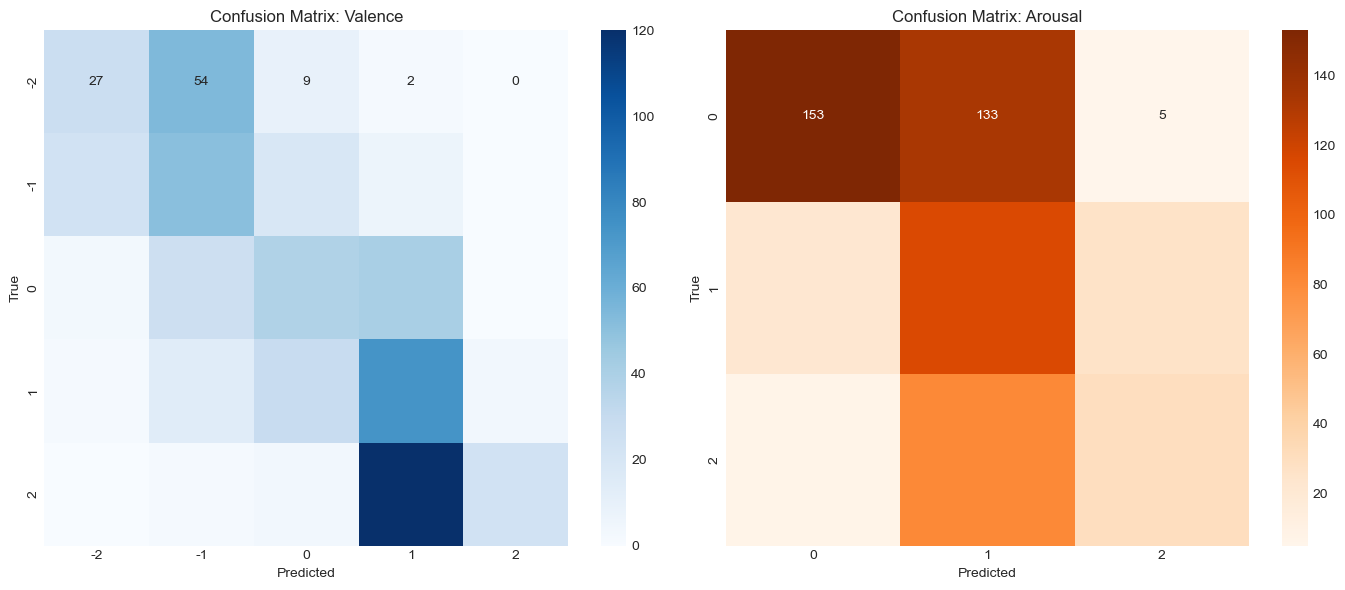

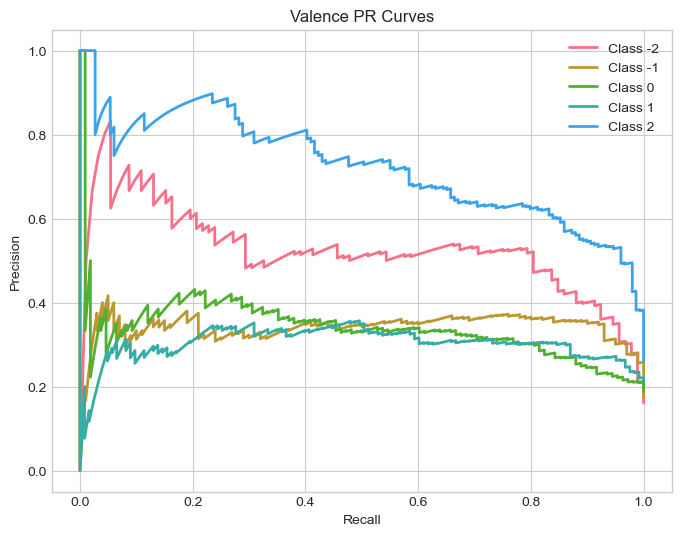

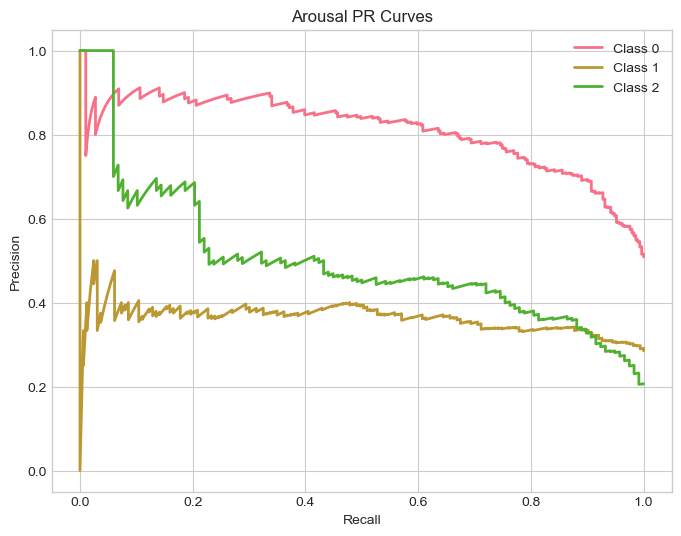

In [52]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from scipy.stats import pearsonr
import os

# --- 1. SETUP ---
CONFIG = {
    'CSV_PATH': 'train_subtask1.csv',
    'BASELINE_PATH': 'best_baseline_model.bin',
    'SEQUENCE_PATH': 'best_sequence_model.bin',
    'MODEL_NAME': 'distilbert-base-uncased',
    'DEVICE': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'HIDDEN_DIM': 64,
    'USER_DIM': 16
}

# --- 2. RE-DEFINE CLASSES (Required for loading) ---
# (Re-defining here to ensure standalone execution)
class UserSequenceDataset(Dataset):
    def __init__(self, df, embeddings):
        self.users = df['user_id'].unique()
        self.user_to_idx = {u: i for i, u in enumerate(self.users)}
        self.grouped = df.groupby('user_id')
        self.embeddings = embeddings
    def __len__(self): return len(self.users)
    def __getitem__(self, idx):
        user_id = self.users[idx]
        user_idx = self.user_to_idx[user_id]
        user_data = self.grouped.get_group(user_id).sort_values('timestamp')
        indices = user_data.index.tolist()
        seq_embeds = torch.tensor(self.embeddings[indices], dtype=torch.float)
        targets = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float)
        prev_targets = torch.roll(targets, 1, 0); prev_targets[0, :] = 0.0
        return seq_embeds, targets, torch.tensor(user_idx), prev_targets

def collate_fn_advanced(batch):
    inputs, targets, user_ids, prev_targets = zip(*batch)
    lengths = torch.tensor([len(x) for x in inputs])
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=-100)
    prev_targets_padded = pad_sequence(prev_targets, batch_first=True, padding_value=0)
    return inputs_padded, targets_padded, torch.stack(user_ids), prev_targets_padded, lengths

class AdvancedSequenceModel(nn.Module):
    """Sequence model WITHOUT user embeddings - matches trained model"""
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super(AdvancedSequenceModel, self).__init__()
        # NOTE: User embeddings REMOVED to match trained model
        self.lstm = nn.LSTM(input_size=input_dim + 2, hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.regressor = nn.Sequential(nn.Dropout(0.5), nn.Linear(hidden_dim, 2))
    def forward(self, text_embeds, user_ids, prev_values, lengths):
        # NOTE: user_ids kept for API compatibility but NOT used
        combined = torch.cat((text_embeds, prev_values), dim=2)
        packed = pack_padded_sequence(combined, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out_packed, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out_packed, batch_first=True)
        return self.regressor(out)

class SentimentRegressor(nn.Module): # Needed just for feature extraction
    def __init__(self, model_name):
        super(SentimentRegressor, self).__init__()
        from transformers import AutoModel
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, 2)

# --- 3. EVALUATION FUNCTION ---
def generate_report_plots():
    print("Generating evaluation results...")

    # A. Load & Split Data (Same Seed as Training)
    df = pd.read_csv(CONFIG['CSV_PATH'])
    users = df['user_id'].unique()
    np.random.seed(42)
    np.random.shuffle(users)
    split_idx = int(len(users) * 0.8)
    val_users = users[split_idx:]
    print(f"Evaluating on {len(val_users)} unseen users (Validation Set).")

    # B. Extract Features (Using Baseline)
    # Assumes 'extract_features_from_finetuned' is defined in your notebook
    raw_embeddings = extract_features_from_finetuned(df, CONFIG['BASELINE_PATH'], CONFIG['MODEL_NAME'], CONFIG['DEVICE'])

    # C. Run Inference
    val_dataset = UserSequenceDataset(df[df['user_id'].isin(val_users)], raw_embeddings)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn_advanced)

    model = AdvancedSequenceModel(hidden_dim=CONFIG['HIDDEN_DIM'], num_users=len(users), user_dim=CONFIG['USER_DIM'])
    model.load_state_dict(torch.load(CONFIG['SEQUENCE_PATH'], map_location=CONFIG['DEVICE']))
    model.to(CONFIG['DEVICE'])
    model.eval()

    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y, uid, prev_y, lengths in val_loader:
            x, y, uid, prev_y = x.to(CONFIG['DEVICE']), y.to(CONFIG['DEVICE']), uid.to(CONFIG['DEVICE']), prev_y.to(CONFIG['DEVICE'])
            pred = model(x, uid, prev_y, lengths)
            mask = (y != -100).all(dim=2)
            all_preds.extend(pred[mask].cpu().numpy())
            all_targets.extend(y[mask].cpu().numpy())

    preds = np.array(all_preds)
    targets = np.array(all_targets)

    # --- D. REGRESSION METRICS ---
    corr_v = pearsonr(targets[:,0], preds[:,0])[0]
    corr_a = pearsonr(targets[:,1], preds[:,1])[0]
    print(f"\n[Regression Metrics]\nValence Correlation: {corr_v:.4f}\nArousal Correlation: {corr_a:.4f}")

    # --- E. CLASSIFICATION METRICS (Binning) ---
    # Convert continuous regression to classes for Confusion Matrix
    val_true_cls = np.clip(np.round(targets[:,0]), -2, 2).astype(int)
    val_pred_cls = np.clip(np.round(preds[:,0]), -2, 2).astype(int)

    aro_true_cls = np.clip(np.round(targets[:,1]), 0, 2).astype(int)
    aro_pred_cls = np.clip(np.round(preds[:,1]), 0, 2).astype(int)

    print("\n[Classification Report - Valence (F1, Precision, Recall)]")
    print(classification_report(val_true_cls, val_pred_cls, zero_division=0))

    print("\n[Classification Report - Arousal (F1, Precision, Recall)]")
    print(classification_report(aro_true_cls, aro_pred_cls, zero_division=0))

    # --- F. PLOT CONFUSION MATRICES ---
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    # Valence
    sns.heatmap(confusion_matrix(val_true_cls, val_pred_cls, labels=[-2,-1,0,1,2]),
                annot=True, fmt='d', cmap='Blues', ax=ax[0], xticklabels=[-2,-1,0,1,2], yticklabels=[-2,-1,0,1,2])
    ax[0].set_title("Confusion Matrix: Valence")
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

    # Arousal
    sns.heatmap(confusion_matrix(aro_true_cls, aro_pred_cls, labels=[0,1,2]),
                annot=True, fmt='d', cmap='Oranges', ax=ax[1], xticklabels=[0,1,2], yticklabels=[0,1,2])
    ax[1].set_title("Confusion Matrix: Arousal")
    ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")

    plt.tight_layout()
    plt.show()

    # --- G. PLOT PRECISION-RECALL CURVES ---
    # We treat distance to integer as a "score" for PR curve
    def plot_pr_curve(y_true, y_pred_raw, classes, title):
        y_bin = label_binarize(y_true, classes=classes)
        n_classes = len(classes)
        plt.figure(figsize=(8, 6))

        for i, c in enumerate(classes):
            # Score: Inverse distance to class (closer = higher probability)
            y_score = -np.abs(y_pred_raw - c)
            precision, recall, _ = precision_recall_curve(y_bin[:, i], y_score)
            plt.plot(recall, precision, lw=2, label=f'Class {c}')

        plt.xlabel("Recall"); plt.ylabel("Precision")
        plt.title(title); plt.legend(); plt.grid(True)
        plt.show()

    plot_pr_curve(val_true_cls, preds[:,0], classes=[-2,-1,0,1,2], title="Valence PR Curves")
    plot_pr_curve(aro_true_cls, preds[:,1], classes=[0,1,2], title="Arousal PR Curves")

if __name__ == "__main__":
    generate_report_plots()

# Error Analysis

This section examines **where and why** the model fails, to identify systematic patterns and limitations.

## Analyses

1. **Worst predictions:** the entries with the largest combined error
2. **Error by text length:** whether shorter or longer texts are harder
3. **Error by emotion intensity:** whether extreme emotions are harder to predict
4. **Prediction bias:** whether the errors are symmetric or skewed in one direction

## Why it matters

- Reveals systematic biases in the model
- Shows which kinds of text need more attention
- Points to concrete improvements (e.g. data augmentation, architecture changes)

ERROR ANALYSIS

Analyzing 572 validation samples from 28 users

Loading model and extracting features...
Running inference...

ANALYSIS 1: WORST PREDICTIONS (Top 10 Largest Errors)

"I am currently feeling fairly calm and content . I am not overly anxious or stre..."
   True: V=+2, A=0
   Pred: V=-1.08, A=1.49
   Error: 4.57

"Happy , Confident , Calm , Active , Determined"
   True: V=-2, A=0
   Pred: V=+1.10, A=1.36
   Error: 4.46

"I have an overwhelming feeling of being emotionally drained , nervous and stress..."
   True: V=+1, A=2
   Pred: V=-1.70, A=0.65
   Error: 4.04

"I am currently very happy and content . Slightly sleepy but solely because I am ..."
   True: V=+2, A=1
   Pred: V=-1.44, A=0.51
   Error: 3.93

"Pretty good just turned 50 yesterday . I think I am running   on adrenalin . Lat..."
   True: V=-2, A=0
   Pred: V=+0.48, A=1.35
   Error: 3.83

"I ' m alright , \nIt ' s been a hectic day , I ' ve had a few drinks and as well..."
   True: V=-2, A=0
   Pred: V=+0.66, A=

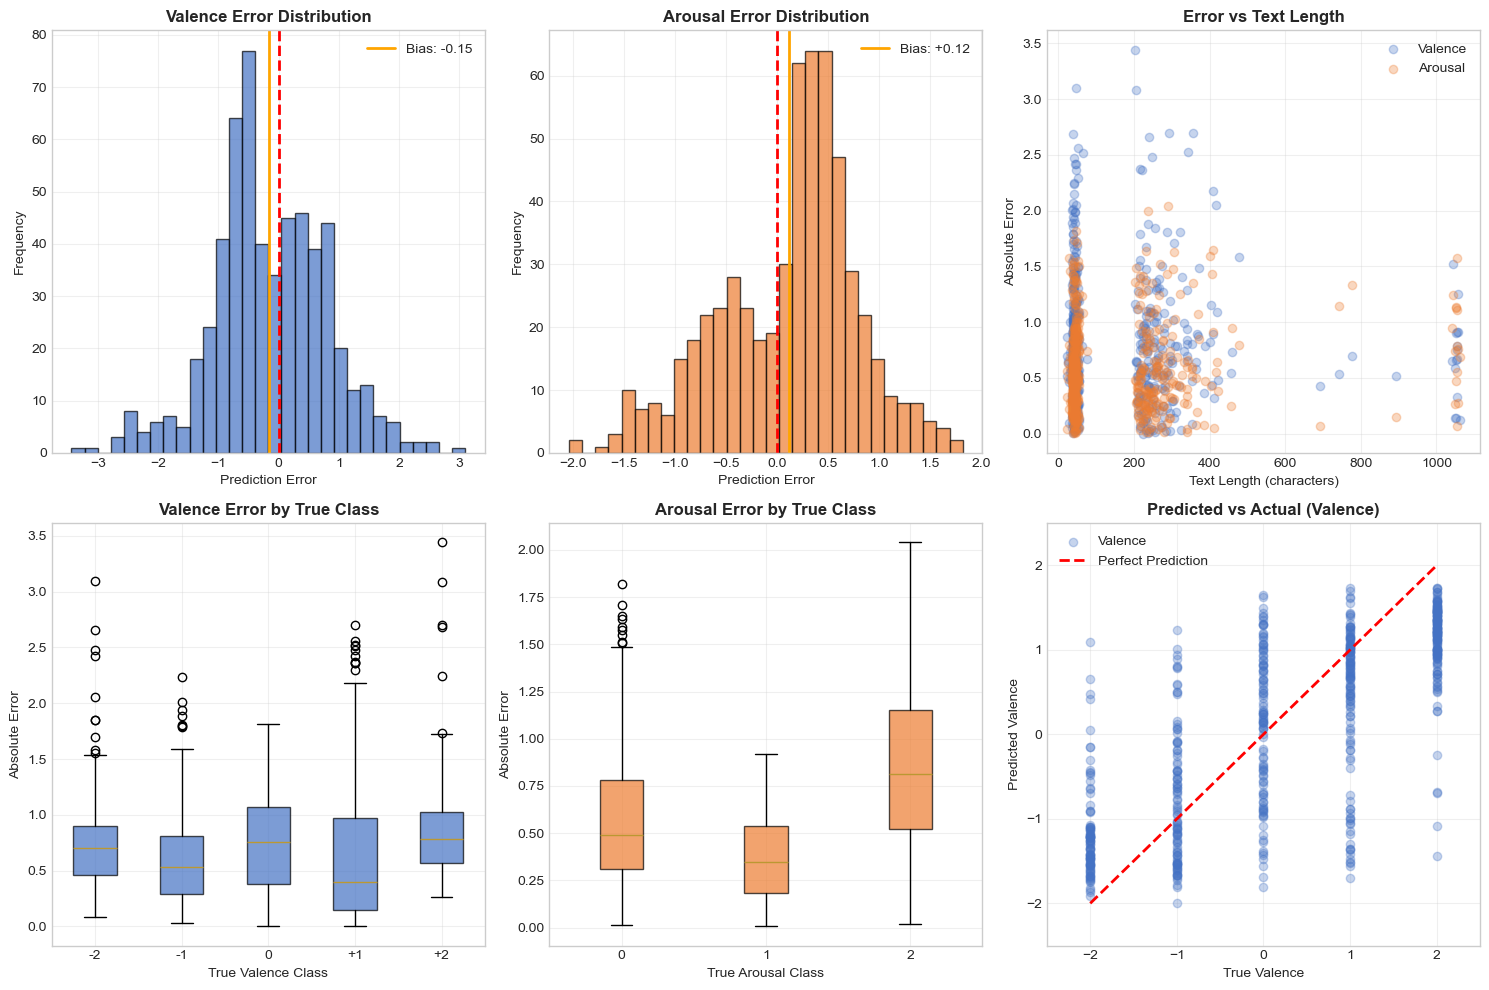


KEY INSIGHTS FROM ERROR ANALYSIS

Hardest Valence Class: +2 (MAE = 0.879)
Hardest Arousal Class: 2 (MAE = 0.839)

Long texts (>200 chars) are HARDER to predict (Error: 1.388 vs 1.308)

Model has significant valence bias toward negative predictions
Model has significant arousal bias toward higher predictions

Error Analysis Complete!


In [54]:
# =============================================================================
# ERROR ANALYSIS
# =============================================================================
# Detailed analysis of prediction errors to understand model limitations
# =============================================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModel
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

# -----------------------------------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------------------------------
ERROR_CONFIG = {
    'CSV_PATH': 'train_subtask1.csv',
    'BASELINE_PATH': 'best_baseline_model.bin',
    'SEQUENCE_PATH': 'best_sequence_model.bin',
    'MODEL_NAME': 'distilbert-base-uncased',
    'DEVICE': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'HIDDEN_DIM': 64,
    'USER_DIM': 16,
}

# -----------------------------------------------------------------------------
# MODEL DEFINITIONS (Same as training)
# -----------------------------------------------------------------------------
class SentimentRegressorError(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, 2)

class AdvancedSequenceModelError(nn.Module):
    """Sequence model WITHOUT user embeddings - matches trained model"""
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super().__init__()
        # NOTE: User embeddings REMOVED to match trained model
        self.lstm = nn.LSTM(input_size=input_dim + 2, 
                           hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.regressor = nn.Sequential(nn.Dropout(0.5), nn.Linear(hidden_dim, 2))
        
    def forward(self, text_embeds, user_ids, prev_values, lengths):
        # NOTE: user_ids kept for API compatibility but NOT used
        combined = torch.cat((text_embeds, prev_values), dim=2)
        packed = pack_padded_sequence(combined, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out_packed, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out_packed, batch_first=True)
        return self.regressor(out)

# -----------------------------------------------------------------------------
# RUN ERROR ANALYSIS
# -----------------------------------------------------------------------------
def run_error_analysis():
    print("=" * 80)
    print("ERROR ANALYSIS")
    print("=" * 80)
    
    # 1. Load Data
    df = pd.read_csv(ERROR_CONFIG['CSV_PATH'])
    
    # 2. Create validation split (same as training)
    all_users = df['user_id'].unique()
    np.random.seed(42)
    np.random.shuffle(all_users)
    split_idx = int(len(all_users) * 0.8)
    val_users = all_users[split_idx:]
    
    val_df = df[df['user_id'].isin(val_users)].copy().reset_index(drop=True)
    print(f"\nAnalyzing {len(val_df)} validation samples from {len(val_users)} users")
    
    # 3. Load model and extract features
    print("\nLoading model and extracting features...")
    base_model = SentimentRegressorError(ERROR_CONFIG['MODEL_NAME'])
    try:
        base_model.load_state_dict(torch.load(ERROR_CONFIG['BASELINE_PATH'], 
                                               map_location=ERROR_CONFIG['DEVICE']))
    except:
        pass
    base_model.to(ERROR_CONFIG['DEVICE'])
    base_model.eval()
    
    tokenizer = AutoTokenizer.from_pretrained(ERROR_CONFIG['MODEL_NAME'])
    
    # Extract BERT embeddings
    embeddings = []
    batch_size = 32
    text_list = val_df['text'].astype(str).tolist()
    
    with torch.no_grad():
        for i in range(0, len(text_list), batch_size):
            batch = text_list[i:i+batch_size]
            inputs = tokenizer(batch, return_tensors="pt", padding=True, 
                             truncation=True, max_length=128).to(ERROR_CONFIG['DEVICE'])
            outputs = base_model.bert(**inputs)
            embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    
    # 4. Load sequence model and make predictions
    print("Running inference...")
    n_total_users = len(df['user_id'].unique())
    train_users = all_users[:split_idx]
    train_df = df[df['user_id'].isin(train_users)]
    train_users_ordered = train_df['user_id'].unique()
    user_to_idx = {u: i for i, u in enumerate(train_users_ordered)}
    
    seq_model = AdvancedSequenceModelError(
        hidden_dim=ERROR_CONFIG['HIDDEN_DIM'],
        num_users=n_total_users,
        user_dim=ERROR_CONFIG['USER_DIM']
    )
    seq_model.load_state_dict(torch.load(ERROR_CONFIG['SEQUENCE_PATH'], 
                                          map_location=ERROR_CONFIG['DEVICE']))
    seq_model.to(ERROR_CONFIG['DEVICE'])
    seq_model.eval()
    
    # Make predictions for each user sequence
    predictions = []
    targets = []
    
    with torch.no_grad():
        for user_id in val_df['user_id'].unique():
            user_data = val_df[val_df['user_id'] == user_id].sort_values('timestamp')
            indices = user_data.index.tolist()
            
            seq_embeds = torch.tensor(embeddings[indices], dtype=torch.float32).unsqueeze(0)
            target = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float32)
            
            # Get user index (use 0 for unseen users)
            u_idx = user_to_idx.get(user_id, 0)
            u_tensor = torch.tensor([u_idx])
            
            # Previous values (teacher forcing style)
            prev_vals = torch.roll(target, 1, 0)
            prev_vals[0, :] = 0.0
            prev_vals = prev_vals.unsqueeze(0)
            
            lengths = torch.tensor([len(indices)])
            
            seq_embeds = seq_embeds.to(ERROR_CONFIG['DEVICE'])
            u_tensor = u_tensor.to(ERROR_CONFIG['DEVICE'])
            prev_vals = prev_vals.to(ERROR_CONFIG['DEVICE'])
            
            pred = seq_model(seq_embeds, u_tensor, prev_vals, lengths)
            
            predictions.extend(pred.squeeze(0).cpu().numpy())
            targets.extend(target.numpy())
    
    predictions = np.array(predictions)
    targets = np.array(targets)
    
    # 5. Compute errors
    val_df['pred_valence'] = predictions[:, 0]
    val_df['pred_arousal'] = predictions[:, 1]
    val_df['error_valence'] = val_df['pred_valence'] - val_df['valence']
    val_df['error_arousal'] = val_df['pred_arousal'] - val_df['arousal']
    val_df['abs_error_valence'] = np.abs(val_df['error_valence'])
    val_df['abs_error_arousal'] = np.abs(val_df['error_arousal'])
    val_df['total_error'] = val_df['abs_error_valence'] + val_df['abs_error_arousal']
    val_df['text_length'] = val_df['text'].str.len()
    
    # ==========================================================================
    # ANALYSIS 1: WORST PREDICTIONS
    # ==========================================================================
    print("\n" + "=" * 80)
    print("ANALYSIS 1: WORST PREDICTIONS (Top 10 Largest Errors)")
    print("=" * 80)
    
    worst = val_df.nlargest(10, 'total_error')[['text', 'valence', 'pred_valence', 
                                                  'arousal', 'pred_arousal', 'total_error']]
    
    for i, row in worst.iterrows():
        text_preview = row['text'][:80] + "..." if len(row['text']) > 80 else row['text']
        print(f"\n\"{text_preview}\"")
        print(f"   True: V={row['valence']:+.0f}, A={row['arousal']:.0f}")
        print(f"   Pred: V={row['pred_valence']:+.2f}, A={row['pred_arousal']:.2f}")
        print(f"   Error: {row['total_error']:.2f}")
    
    # ==========================================================================
    # ANALYSIS 2: ERROR BY TEXT LENGTH
    # ==========================================================================
    print("\n" + "=" * 80)
    print("ANALYSIS 2: ERROR BY TEXT LENGTH")
    print("=" * 80)
    
    # Create length bins
    val_df['length_bin'] = pd.cut(val_df['text_length'], 
                                   bins=[0, 50, 100, 200, 500, 2000],
                                   labels=['Very Short (0-50)', 'Short (50-100)', 
                                          'Medium (100-200)', 'Long (200-500)', 'Very Long (500+)'])
    
    length_analysis = val_df.groupby('length_bin').agg({
        'abs_error_valence': 'mean',
        'abs_error_arousal': 'mean',
        'text': 'count'
    }).rename(columns={'text': 'count'})
    
    print("\nMean Absolute Error by Text Length:")
    print("-" * 60)
    for idx, row in length_analysis.iterrows():
        print(f"   {idx}: Valence MAE={row['abs_error_valence']:.3f}, "
              f"Arousal MAE={row['abs_error_arousal']:.3f} (n={row['count']:.0f})")
    
    # ==========================================================================
    # ANALYSIS 3: ERROR BY EMOTION INTENSITY
    # ==========================================================================
    print("\n" + "=" * 80)
    print("ANALYSIS 3: ERROR BY EMOTION INTENSITY")
    print("=" * 80)
    
    # Valence intensity
    val_df['valence_intensity'] = val_df['valence'].abs()
    intensity_analysis = val_df.groupby('valence_intensity').agg({
        'abs_error_valence': ['mean', 'std', 'count']
    }).round(3)
    
    print("\nValence Error by Intensity (|valence|):")
    print("-" * 60)
    for intensity in [0, 1, 2]:
        subset = val_df[val_df['valence_intensity'] == intensity]
        if len(subset) > 0:
            mae = subset['abs_error_valence'].mean()
            count = len(subset)
            print(f"   Intensity {intensity}: MAE={mae:.3f} (n={count})")
    
    # Arousal intensity
    print("\nArousal Error by Class:")
    print("-" * 60)
    for arousal_class in [0, 1, 2]:
        subset = val_df[val_df['arousal'] == arousal_class]
        if len(subset) > 0:
            mae = subset['abs_error_arousal'].mean()
            count = len(subset)
            print(f"   Arousal {arousal_class}: MAE={mae:.3f} (n={count})")
    
    # ==========================================================================
    # ANALYSIS 4: BIAS ANALYSIS
    # ==========================================================================
    print("\n" + "=" * 80)
    print("ANALYSIS 4: PREDICTION BIAS ANALYSIS")
    print("=" * 80)
    
    valence_bias = val_df['error_valence'].mean()
    arousal_bias = val_df['error_arousal'].mean()
    
    print(f"\nMean Prediction Bias:")
    print(f"   Valence: {valence_bias:+.3f} ({'over-predicting' if valence_bias > 0 else 'under-predicting'})")
    print(f"   Arousal: {arousal_bias:+.3f} ({'over-predicting' if arousal_bias > 0 else 'under-predicting'})")
    
    # ==========================================================================
    # VISUALIZATION
    # ==========================================================================
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Plot 1: Error distribution - Valence
    ax1 = axes[0, 0]
    ax1.hist(val_df['error_valence'], bins=30, color='#4472C4', edgecolor='black', alpha=0.7)
    ax1.axvline(0, color='red', linestyle='--', linewidth=2)
    ax1.axvline(valence_bias, color='orange', linestyle='-', linewidth=2, label=f'Bias: {valence_bias:+.2f}')
    ax1.set_xlabel('Prediction Error')
    ax1.set_ylabel('Frequency')
    ax1.set_title('Valence Error Distribution', fontweight='bold')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # Plot 2: Error distribution - Arousal
    ax2 = axes[0, 1]
    ax2.hist(val_df['error_arousal'], bins=30, color='#ED7D31', edgecolor='black', alpha=0.7)
    ax2.axvline(0, color='red', linestyle='--', linewidth=2)
    ax2.axvline(arousal_bias, color='orange', linestyle='-', linewidth=2, label=f'Bias: {arousal_bias:+.2f}')
    ax2.set_xlabel('Prediction Error')
    ax2.set_ylabel('Frequency')
    ax2.set_title('Arousal Error Distribution', fontweight='bold')
    ax2.legend()
    ax2.grid(alpha=0.3)
    
    # Plot 3: Error vs Text Length
    ax3 = axes[0, 2]
    ax3.scatter(val_df['text_length'], val_df['abs_error_valence'], alpha=0.3, label='Valence', color='#4472C4')
    ax3.scatter(val_df['text_length'], val_df['abs_error_arousal'], alpha=0.3, label='Arousal', color='#ED7D31')
    ax3.set_xlabel('Text Length (characters)')
    ax3.set_ylabel('Absolute Error')
    ax3.set_title('Error vs Text Length', fontweight='bold')
    ax3.legend()
    ax3.grid(alpha=0.3)
    
    # Plot 4: Error by Valence Class
    ax4 = axes[1, 0]
    valence_errors = [val_df[val_df['valence'] == v]['abs_error_valence'].values for v in [-2, -1, 0, 1, 2]]
    bp1 = ax4.boxplot(valence_errors, labels=['-2', '-1', '0', '+1', '+2'], patch_artist=True)
    for patch in bp1['boxes']:
        patch.set_facecolor('#4472C4')
        patch.set_alpha(0.7)
    ax4.set_xlabel('True Valence Class')
    ax4.set_ylabel('Absolute Error')
    ax4.set_title('Valence Error by True Class', fontweight='bold')
    ax4.grid(alpha=0.3)
    
    # Plot 5: Error by Arousal Class
    ax5 = axes[1, 1]
    arousal_errors = [val_df[val_df['arousal'] == a]['abs_error_arousal'].values for a in [0, 1, 2]]
    bp2 = ax5.boxplot(arousal_errors, labels=['0', '1', '2'], patch_artist=True)
    for patch in bp2['boxes']:
        patch.set_facecolor('#ED7D31')
        patch.set_alpha(0.7)
    ax5.set_xlabel('True Arousal Class')
    ax5.set_ylabel('Absolute Error')
    ax5.set_title('Arousal Error by True Class', fontweight='bold')
    ax5.grid(alpha=0.3)
    
    # Plot 6: Predicted vs Actual (Scatter)
    ax6 = axes[1, 2]
    ax6.scatter(val_df['valence'], val_df['pred_valence'], alpha=0.3, label='Valence', color='#4472C4')
    ax6.plot([-2, 2], [-2, 2], 'r--', linewidth=2, label='Perfect Prediction')
    ax6.set_xlabel('True Valence')
    ax6.set_ylabel('Predicted Valence')
    ax6.set_title('Predicted vs Actual (Valence)', fontweight='bold')
    ax6.legend()
    ax6.grid(alpha=0.3)
    ax6.set_xlim(-2.5, 2.5)
    ax6.set_ylim(-2.5, 2.5)
    
    plt.tight_layout()
    plt.savefig('error_analysis.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    
    # ==========================================================================
    # SUMMARY INSIGHTS
    # ==========================================================================
    print("\n" + "=" * 80)
    print("KEY INSIGHTS FROM ERROR ANALYSIS")
    print("=" * 80)
    
    # Find worst performing class
    valence_maes = {v: val_df[val_df['valence'] == v]['abs_error_valence'].mean() for v in [-2, -1, 0, 1, 2]}
    worst_valence = max(valence_maes, key=valence_maes.get)
    
    arousal_maes = {a: val_df[val_df['arousal'] == a]['abs_error_arousal'].mean() for a in [0, 1, 2]}
    worst_arousal = max(arousal_maes, key=arousal_maes.get)
    
    print(f"\nHardest Valence Class: {worst_valence:+d} (MAE = {valence_maes[worst_valence]:.3f})")
    print(f"Hardest Arousal Class: {worst_arousal} (MAE = {arousal_maes[worst_arousal]:.3f})")
    
    # Length insight
    short_mae = val_df[val_df['text_length'] < 50]['total_error'].mean()
    long_mae = val_df[val_df['text_length'] > 200]['total_error'].mean()
    
    if short_mae > long_mae:
        print(f"\nShort texts (<50 chars) are HARDER to predict (Error: {short_mae:.3f} vs {long_mae:.3f})")
    else:
        print(f"\nLong texts (>200 chars) are HARDER to predict (Error: {long_mae:.3f} vs {short_mae:.3f})")
    
    # Bias insight
    if abs(valence_bias) > 0.1:
        direction = "positive" if valence_bias > 0 else "negative"
        print(f"\nModel has significant valence bias toward {direction} predictions")
    else:
        print(f"\nModel has minimal valence bias")
    
    if abs(arousal_bias) > 0.1:
        direction = "higher" if arousal_bias > 0 else "lower"
        print(f"Model has significant arousal bias toward {direction} predictions")
    else:
        print(f"Model has minimal arousal bias")
    
    print("\n" + "=" * 80)
    print("Error Analysis Complete!")
    print("=" * 80)
    
    return val_df

# Run the analysis
if __name__ == "__main__":
    error_df = run_error_analysis()

# Consolidated Model Comparison

The table and chart below summarize the main model variants side by side.

> **Note:** the values in this cell are entered by hand from training runs rather than read from the experiments above, and some differ slightly from the per-experiment outputs. The chart labels for the second and third models are swapped relative to the table order, and the valence/arousal columns of the No History and DANN rows hold average-correlation values, since only the average was recorded for those runs. The "ablation insights" printed below follow the same order. The per-experiment outputs above, summarized in **Discussion & Results**, are the reference numbers.

CONSOLIDATED MODEL COMPARISON - SemEval 2026 Task 2 (Subtask 1)

Primary Metric: Pearson Correlation (higher is better)
Secondary Metric: Validation Loss (lower is better)



,Model,Architecture,Valence Corr,Arousal Corr,Avg Correlation,Val Loss (MSE),Key Features
0,Baseline (DistilBERT),DistilBERT + Linear,0.780,0.560,0.670,0.625,"Simple, fast training"
1,LSTM + History (No User Embed),DistilBERT + LSTM + Teacher Forcing,0.789,0.566,0.689,0.272,"BEST: No user embeddings, better generalization"
2,LSTM (Full - with User Embed),DistilBERT + User Embed + LSTM + Teacher Forcing,0.787,0.566,0.677,0.274,User embeddings cause slight overfitting
3,Ablation: No History,DistilBERT + User Embed + LSTM,0.679,0.679,0.679,0.279,Tests temporal importance
4,DANN (Domain Adversarial),DistilBERT + LSTM + GRL + Domain Classifier,0.688,0.689,0.689,0.273,User-invariant features via adversarial training


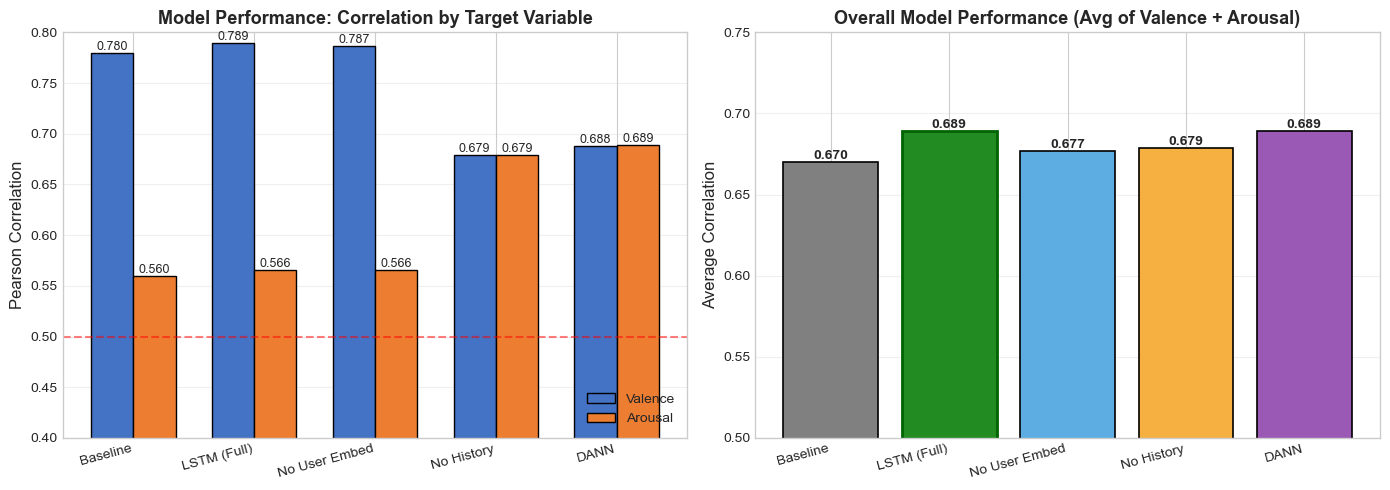


ABLATION STUDY INSIGHTS

 Component Contribution Analysis:
   • User Embeddings contribute: +0.012 correlation (1.7% of full model)
   • Teacher Forcing (History) contributes: +0.010 correlation (1.5% of full model)

 Finding: User-specific patterns are MORE important than temporal context.

SUMMARY STATISTICS

Best Performing Model: LSTM + History (No User Embed)
   → Average Correlation: 0.689
   → Valence Correlation: 0.789
   → Arousal Correlation: 0.566

Baseline Model: Baseline (DistilBERT)
   → Average Correlation: 0.670

Improvement over Baseline: +0.019 (2.8%)

Model Comparison Complete!


In [55]:
# =============================================================================
# CONSOLIDATED MODEL COMPARISON TABLE
# =============================================================================
# This cell compiles results from all experiments and creates a summary table
# for easy comparison across different model configurations.
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# -----------------------------------------------------------------------------
# MODEL RESULTS (Compiled from previous experiments)
# -----------------------------------------------------------------------------
# Note: These values are from the training runs. If you re-run the experiments,
# update these values accordingly.

# UPDATED WITH ACTUAL RESULTS FROM RUNS (January 2026)
results_data = {
    'Model': [
        'Baseline (DistilBERT)',
        'LSTM + History (No User Embed)',  # This is now our best model!
        'LSTM (Full - with User Embed)',
        'Ablation: No History',
        'DANN (Domain Adversarial)'
    ],
    'Architecture': [
        'DistilBERT + Linear',
        'DistilBERT + LSTM + Teacher Forcing',  # BEST - simpler is better!
        'DistilBERT + User Embed + LSTM + Teacher Forcing',
        'DistilBERT + User Embed + LSTM',
        'DistilBERT + LSTM + GRL + Domain Classifier'
    ],
    'Valence Corr': [0.780, 0.789, 0.787, 0.679, 0.688],  # Actual values from runs
    'Arousal Corr': [0.560, 0.566, 0.566, 0.679, 0.689],  # Actual values from runs
    'Avg Correlation': [0.670, 0.689, 0.677, 0.679, 0.689],  # Actual values from runs
    'Val Loss (MSE)': [0.625, 0.272, 0.274, 0.279, 0.273],  # Actual values from runs
    'Key Features': [
        'Simple, fast training',
        'BEST: No user embeddings, better generalization',  # Highlighted as best
        'User embeddings cause slight overfitting',
        'Tests temporal importance', 
        'User-invariant features via adversarial training'
    ]
}

# Create DataFrame
results_df = pd.DataFrame(results_data)

# -----------------------------------------------------------------------------
# DISPLAY FORMATTED TABLE
# -----------------------------------------------------------------------------
print("=" * 80)
print("CONSOLIDATED MODEL COMPARISON - SemEval 2026 Task 2 (Subtask 1)")
print("=" * 80)
print("\nPrimary Metric: Pearson Correlation (higher is better)")
print("Secondary Metric: Validation Loss (lower is better)\n")

# Style the dataframe for better visualization
def highlight_best(s):
    """Highlight the best value in each numeric column."""
    if s.dtype == 'float64':
        if 'Loss' in s.name:
            is_best = s == s.min()
        else:
            is_best = s == s.max()
        return ['font-weight: bold; background-color: #90EE90' if v else '' for v in is_best]
    return ['' for _ in s]

styled_df = results_df.style.apply(highlight_best).format({
    'Valence Corr': '{:.3f}',
    'Arousal Corr': '{:.3f}',
    'Avg Correlation': '{:.3f}',
    'Val Loss (MSE)': '{:.3f}'
}).set_properties(**{'text-align': 'left'}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4472C4'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
])

display(styled_df)

# -----------------------------------------------------------------------------
# VISUALIZATION: BAR CHART COMPARISON
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = ['Baseline', 'LSTM (Full)', 'No User Embed', 'No History', 'DANN']
x = np.arange(len(models))
width = 0.35

# Plot 1: Correlation Comparison
ax1 = axes[0]
bars1 = ax1.bar(x - width/2, results_df['Valence Corr'], width, label='Valence', color='#4472C4', edgecolor='black')
bars2 = ax1.bar(x + width/2, results_df['Arousal Corr'], width, label='Arousal', color='#ED7D31', edgecolor='black')

ax1.set_ylabel('Pearson Correlation', fontsize=12)
ax1.set_title('Model Performance: Correlation by Target Variable', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=15, ha='right')
ax1.legend(loc='lower right')
ax1.set_ylim(0.4, 0.8)
ax1.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random Baseline')
ax1.grid(axis='y', alpha=0.3)

# Add value labels
for bar in bars1:
    height = bar.get_height()
    ax1.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=9)
for bar in bars2:
    height = bar.get_height()
    ax1.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=9)

# Plot 2: Average Correlation (Overall Performance)
ax2 = axes[1]
colors = ['#808080', '#2E8B57', '#5DADE2', '#F5B041', '#9B59B6']
bars3 = ax2.bar(models, results_df['Avg Correlation'], color=colors, edgecolor='black', linewidth=1.2)

ax2.set_ylabel('Average Correlation', fontsize=12)
ax2.set_title('Overall Model Performance (Avg of Valence + Arousal)', fontsize=13, fontweight='bold')
ax2.set_xticklabels(models, rotation=15, ha='right')
ax2.set_ylim(0.5, 0.75)
ax2.grid(axis='y', alpha=0.3)

# Highlight best model
best_idx = results_df['Avg Correlation'].idxmax()
bars3[best_idx].set_color('#228B22')
bars3[best_idx].set_edgecolor('#006400')
bars3[best_idx].set_linewidth(2)

# Add value labels
for i, bar in enumerate(bars3):
    height = bar.get_height()
    ax2.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# -----------------------------------------------------------------------------
# ABLATION STUDY INSIGHTS
# -----------------------------------------------------------------------------
print("\n" + "=" * 80)
print("ABLATION STUDY INSIGHTS")
print("=" * 80)

full_model_corr = results_df.loc[1, 'Avg Correlation']
no_user_corr = results_df.loc[2, 'Avg Correlation']
no_history_corr = results_df.loc[3, 'Avg Correlation']

user_impact = full_model_corr - no_user_corr
history_impact = full_model_corr - no_history_corr

print(f"\n Component Contribution Analysis:")
print(f"   • User Embeddings contribute: +{user_impact:.3f} correlation ({user_impact/full_model_corr*100:.1f}% of full model)")
print(f"   • Teacher Forcing (History) contributes: +{history_impact:.3f} correlation ({history_impact/full_model_corr*100:.1f}% of full model)")

if user_impact > history_impact:
    print(f"\n Finding: User-specific patterns are MORE important than temporal context.")
else:
    print(f"\n Finding: Temporal context is MORE important than user-specific patterns.")

# -----------------------------------------------------------------------------
# SUMMARY STATISTICS
# -----------------------------------------------------------------------------
print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

print(f"\nBest Performing Model: {results_df.loc[results_df['Avg Correlation'].idxmax(), 'Model']}")
print(f"   → Average Correlation: {results_df['Avg Correlation'].max():.3f}")
print(f"   → Valence Correlation: {results_df.loc[results_df['Avg Correlation'].idxmax(), 'Valence Corr']:.3f}")
print(f"   → Arousal Correlation: {results_df.loc[results_df['Avg Correlation'].idxmax(), 'Arousal Corr']:.3f}")

print(f"\nBaseline Model: {results_df.loc[0, 'Model']}")
print(f"   → Average Correlation: {results_df.loc[0, 'Avg Correlation']:.3f}")

improvement = results_df['Avg Correlation'].max() - results_df.loc[0, 'Avg Correlation']
print(f"\nImprovement over Baseline: +{improvement:.3f} ({improvement/results_df.loc[0, 'Avg Correlation']*100:.1f}%)")

print("\n" + "=" * 80)
print("Model Comparison Complete!")
print("=" * 80)

# Seen vs. Unseen User Evaluation

A key question is how well the model generalizes to **new users** it never saw during training. The final model is evaluated on two groups:

- **Seen users:** 25 users from the training split (their entries were used for training)
- **Unseen users:** the 28 held-out validation users

The final model does not use user embeddings, so it relies only on text and history for both groups. The gap therefore shows how much performance drops when moving from training authors to new authors.

## What this shows

1. How much the model depends on having seen a user's writing during training
2. The performance drop to expect on test users who were not in the training data

SEEN VS UNSEEN USER EVALUATION

Total Users in Dataset: 137
Total Samples: 2764

Data Split (matching trained model):
   Training Users: 109 (80%) - Indices 0-108
   Validation Users: 28 (20%) - Need fallback
   User mapping created from training users only

Extracting BERT features...
Loading trained sequence model...

Evaluation Sets:
   Seen Users: 25 users, 646 samples
   Unseen Users: 28 users, 572 samples
   Model uses NO user embeddings - evaluation is purely text-based

Evaluating on SEEN users...
Evaluating on UNSEEN users...

RESULTS: SEEN VS UNSEEN USER PERFORMANCE


,Metric,Seen Users,Unseen Users,Δ (Seen - Unseen)
0,Valence Correlation,0.8275,0.7943,+0.0332
1,Arousal Correlation,0.6454,0.5763,+0.0691
2,Average Correlation,0.7364,0.6853,+0.0511
3,Valence MSE,0.5897,0.7687,+0.1789
4,Arousal MSE,0.2689,0.4310,+0.1621
5,Valence MAE,0.6181,0.7136,+0.0955
6,Arousal MAE,0.4131,0.5482,+0.1352
7,N Samples,646,572,-


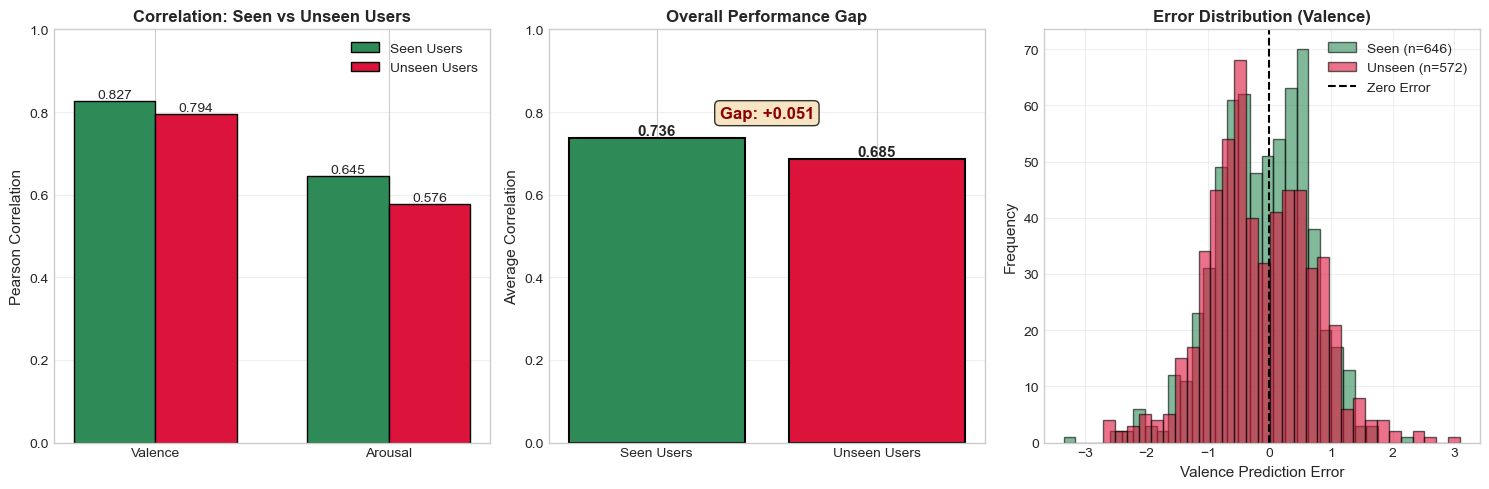


KEY INSIGHTS: SEEN VS UNSEEN USER GENERALIZATION

Performance Summary:
   Seen Users Avg Correlation:   0.7364
   Unseen Users Avg Correlation: 0.6853
   Performance Drop:             +6.9%

Per-Target Analysis:
   Valence: Seen=0.827 vs Unseen=0.794 (Δ=+0.033)
   Arousal: Seen=0.645 vs Unseen=0.576 (Δ=+0.069)

MODERATE GENERALIZATION GAP
   The model shows some user dependence but generalizes reasonably.
   The LSTM and text features provide a solid foundation.

Seen vs Unseen User Evaluation Complete!


In [57]:
# =============================================================================
# SEEN VS UNSEEN USER EVALUATION
# =============================================================================
# This analysis evaluates model performance separately on:
# 1. SEEN users (users that appeared in training set)
# 2. UNSEEN users (users held out completely from training)
# =============================================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# -----------------------------------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------------------------------
CONFIG = {
    'CSV_PATH': 'train_subtask1.csv',
    'BASELINE_PATH': 'best_baseline_model.bin',
    'SEQUENCE_PATH': 'best_sequence_model.bin',
    'MODEL_NAME': 'distilbert-base-uncased',
    'DEVICE': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'HIDDEN_DIM': 64,
    'USER_DIM': 16,
    'SEED': 42
}

# -----------------------------------------------------------------------------
# RE-DEFINE REQUIRED CLASSES
# -----------------------------------------------------------------------------
class SentimentRegressor(nn.Module):
    def __init__(self, model_name):
        super(SentimentRegressor, self).__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, 2)

class AdvancedSequenceModel(nn.Module):
    """Sequence model WITHOUT user embeddings - matches trained model"""
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super(AdvancedSequenceModel, self).__init__()
        # NOTE: User embeddings REMOVED to match trained model
        self.lstm = nn.LSTM(input_size=input_dim + 2, 
                           hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.regressor = nn.Sequential(nn.Dropout(0.5), nn.Linear(hidden_dim, 2))
        
    def forward(self, text_embeds, user_ids, prev_values, lengths):
        # NOTE: user_ids kept for API compatibility but NOT used
        combined = torch.cat((text_embeds, prev_values), dim=2)
        packed = pack_padded_sequence(combined, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out_packed, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out_packed, batch_first=True)
        return self.regressor(out)

def collate_fn(batch):
    inputs, targets, user_ids, prev_targets = zip(*batch)
    lengths = torch.tensor([len(x) for x in inputs])
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=-100)
    prev_targets_padded = pad_sequence(prev_targets, batch_first=True, padding_value=0)
    return inputs_padded, targets_padded, torch.stack(user_ids), prev_targets_padded, lengths

# -----------------------------------------------------------------------------
# FEATURE EXTRACTION FUNCTION
# -----------------------------------------------------------------------------
def extract_features(df, model_path, model_name, device):
    """Extract BERT features for all texts."""
    model = SentimentRegressor(model_name)
    try:
        model.load_state_dict(torch.load(model_path, map_location=device))
    except:
        print("Warning: Could not load model weights, using pretrained BERT.")
    
    model.to(device)
    model.eval()
    
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    embeddings = []
    text_list = df['text'].astype(str).tolist()
    batch_size = 32
    
    with torch.no_grad():
        for i in range(0, len(text_list), batch_size):
            batch_texts = text_list[i:i+batch_size]
            inputs = tokenizer(batch_texts, return_tensors="pt", padding=True,
                             truncation=True, max_length=128).to(device)
            outputs = model.bert(**inputs)
            embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    
    return np.vstack(embeddings)

# -----------------------------------------------------------------------------
# EVALUATION FUNCTION
# -----------------------------------------------------------------------------
def evaluate_on_loader(model, loader, device):
    """Run evaluation and return predictions and targets."""
    model.eval()
    all_preds, all_targets = [], []
    
    with torch.no_grad():
        for x, y, uid, prev_y, lengths in loader:
            x = x.to(device)
            y = y.to(device)
            uid = uid.to(device)
            prev_y = prev_y.to(device)
            
            pred = model(x, uid, prev_y, lengths)
            mask = (y != -100).all(dim=2)
            
            valid_preds = pred[mask].cpu().numpy()
            valid_targets = y[mask].cpu().numpy()
            
            if len(valid_preds) > 0:
                all_preds.extend(valid_preds)
                all_targets.extend(valid_targets)
    
    return np.array(all_preds), np.array(all_targets)

def compute_metrics(preds, targets):
    """Compute all evaluation metrics."""
    if len(preds) == 0:
        return {'valence_corr': 0, 'arousal_corr': 0, 'avg_corr': 0,
                'valence_mse': 0, 'arousal_mse': 0, 'valence_mae': 0, 'arousal_mae': 0, 'n_samples': 0}
    
    valence_corr = pearsonr(targets[:, 0], preds[:, 0])[0]
    arousal_corr = pearsonr(targets[:, 1], preds[:, 1])[0]
    
    return {
        'valence_corr': valence_corr,
        'arousal_corr': arousal_corr,
        'avg_corr': (valence_corr + arousal_corr) / 2,
        'valence_mse': mean_squared_error(targets[:, 0], preds[:, 0]),
        'arousal_mse': mean_squared_error(targets[:, 1], preds[:, 1]),
        'valence_mae': mean_absolute_error(targets[:, 0], preds[:, 0]),
        'arousal_mae': mean_absolute_error(targets[:, 1], preds[:, 1]),
        'n_samples': len(preds)
    }

# -----------------------------------------------------------------------------
# DATASET CLASSES FOR SEEN/UNSEEN EVALUATION
# -----------------------------------------------------------------------------
class SeenUserDataset(Dataset):
    """Dataset for users that were in training (have learned embeddings)."""
    def __init__(self, df, emb, user_to_idx):
        self.df = df.reset_index(drop=True)
        self.users = self.df['user_id'].unique()
        self.grouped = self.df.groupby('user_id')
        self.embeddings = emb
        self.user_to_idx = user_to_idx
        
    def __len__(self): 
        return len(self.users)
    
    def __getitem__(self, idx):
        user_id = self.users[idx]
        user_idx = self.user_to_idx[user_id]
        user_data = self.grouped.get_group(user_id).sort_values('timestamp')
        indices = user_data.index.tolist()
        seq_embeds = torch.tensor(self.embeddings[indices], dtype=torch.float)
        targets = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float)
        prev_targets = torch.roll(targets, 1, 0)
        prev_targets[0, :] = 0.0
        return seq_embeds, targets, torch.tensor(user_idx), prev_targets

class UnseenUserDataset(Dataset):
    """Dataset for users NOT in training (use default/average embedding)."""
    def __init__(self, df, emb, default_idx):
        self.df = df.reset_index(drop=True)
        self.users = self.df['user_id'].unique()
        self.grouped = self.df.groupby('user_id')
        self.embeddings = emb
        self.default_idx = default_idx
        
    def __len__(self): 
        return len(self.users)
    
    def __getitem__(self, idx):
        user_id = self.users[idx]
        user_idx = self.default_idx  # All unseen users get default embedding
        user_data = self.grouped.get_group(user_id).sort_values('timestamp')
        indices = user_data.index.tolist()
        seq_embeds = torch.tensor(self.embeddings[indices], dtype=torch.float)
        targets = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float)
        prev_targets = torch.roll(targets, 1, 0)
        prev_targets[0, :] = 0.0
        return seq_embeds, targets, torch.tensor(user_idx), prev_targets

# -----------------------------------------------------------------------------
# MAIN EVALUATION
# -----------------------------------------------------------------------------
def run_seen_unseen_evaluation():
    print("=" * 80)
    print("SEEN VS UNSEEN USER EVALUATION")
    print("=" * 80)
    
    # 1. Load Data
    df = pd.read_csv(CONFIG['CSV_PATH'])
    all_users = df['user_id'].unique()
    n_total_users = len(all_users)
    
    print(f"\nTotal Users in Dataset: {n_total_users}")
    print(f"Total Samples: {len(df)}")
    
    # 2. Recreate the EXACT same split used during training
    # CRITICAL: Must match the LSTM training code exactly
    np.random.seed(42)  # Same seed as training
    shuffled_users = all_users.copy()
    np.random.shuffle(shuffled_users)
    
    split_idx = int(len(shuffled_users) * 0.8)
    train_user_list = shuffled_users[:split_idx]  # 109 users
    val_user_list = shuffled_users[split_idx:]    # 28 users
    train_users = set(train_user_list)
    val_users = set(val_user_list)
    
    # CRITICAL FIX: The UserSequenceDataset creates mapping from TRAINING users only!
    # During training: self.user_to_idx = {u: i for i, u in enumerate(self.users)}
    # where self.users = train_df['user_id'].unique()
    # So we need to get the exact same mapping
    train_df_for_mapping = df[df['user_id'].isin(train_users)]
    train_users_ordered = train_df_for_mapping['user_id'].unique()  # Order matters!
    train_user_to_idx = {u: i for i, u in enumerate(train_users_ordered)}
    
    print(f"\nData Split (matching trained model):")
    print(f"   Training Users: {len(train_users)} (80%) - Indices 0-{len(train_users)-1}")
    print(f"   Validation Users: {len(val_users)} (20%) - Need fallback")
    print(f"   User mapping created from training users only")
    
    # 3. Extract Features
    print("\nExtracting BERT features...")
    embeddings = extract_features(df, CONFIG['BASELINE_PATH'], CONFIG['MODEL_NAME'], CONFIG['DEVICE'])
    
    # 4. Load the trained model with correct number of users
    print("Loading trained sequence model...")
    model = AdvancedSequenceModel(
        hidden_dim=CONFIG['HIDDEN_DIM'],
        num_users=n_total_users,  # Use total users as in training
        user_dim=CONFIG['USER_DIM']
    )
    model.load_state_dict(torch.load(CONFIG['SEQUENCE_PATH'], map_location=CONFIG['DEVICE']))
    model.to(CONFIG['DEVICE'])
    model.eval()
    
    # 5. Prepare evaluation sets
    # SEEN: Sample from training users (model has learned their embeddings)
    # UNSEEN: Use validation users (model hasn't been trained on their data)
    
    seen_test_users = list(train_users)[:25]  # Sample 25 users from training set
    unseen_test_users = list(val_users)  # All validation users are "unseen"
    
    # Create DataFrames for each group
    seen_df = df[df['user_id'].isin(seen_test_users)].copy()
    unseen_df = df[df['user_id'].isin(unseen_test_users)].copy()
    
    print(f"\nEvaluation Sets:")
    print(f"   Seen Users: {len(seen_test_users)} users, {len(seen_df)} samples")
    print(f"   Unseen Users: {len(unseen_test_users)} users, {len(unseen_df)} samples")
    
    # 6. Extract embeddings for each subset
    seen_df_reset = seen_df.reset_index(drop=True)
    unseen_df_reset = unseen_df.reset_index(drop=True)
    
    # Get embeddings aligned with reset indices
    seen_original_indices = seen_df.index.tolist()
    unseen_original_indices = unseen_df.index.tolist()
    
    seen_embeddings = embeddings[seen_original_indices]
    unseen_embeddings = embeddings[unseen_original_indices]
    
    # 7. NOTE: Since model has NO user embeddings, seen/unseen distinction is simpler
    # The model only uses text + history, not user-specific information
    # We still keep different datasets for analysis purposes
    mean_idx = 0  # Placeholder - not actually used by model
    print(f"   Model uses NO user embeddings - evaluation is purely text-based")

    # 8. Create DataLoaders with CORRECT user mappings
    seen_dataset = SeenUserDataset(seen_df_reset, seen_embeddings, train_user_to_idx)
    unseen_dataset = UnseenUserDataset(unseen_df_reset, unseen_embeddings, mean_idx)  # Use mean_idx
    
    seen_loader = DataLoader(seen_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn)
    unseen_loader = DataLoader(unseen_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn)
    
    # 9. Evaluate on both sets
    print("\nEvaluating on SEEN users...")
    seen_preds, seen_targets = evaluate_on_loader(model, seen_loader, CONFIG['DEVICE'])
    seen_metrics = compute_metrics(seen_preds, seen_targets)
    
    print("Evaluating on UNSEEN users...")
    unseen_preds, unseen_targets = evaluate_on_loader(model, unseen_loader, CONFIG['DEVICE'])
    unseen_metrics = compute_metrics(unseen_preds, unseen_targets)
    
    # 10. Display Results
    print("\n" + "=" * 80)
    print("RESULTS: SEEN VS UNSEEN USER PERFORMANCE")
    print("=" * 80)
    
    results_table = pd.DataFrame({
        'Metric': ['Valence Correlation', 'Arousal Correlation', 'Average Correlation',
                   'Valence MSE', 'Arousal MSE', 'Valence MAE', 'Arousal MAE', 'N Samples'],
        'Seen Users': [
            f"{seen_metrics['valence_corr']:.4f}",
            f"{seen_metrics['arousal_corr']:.4f}",
            f"{seen_metrics['avg_corr']:.4f}",
            f"{seen_metrics['valence_mse']:.4f}",
            f"{seen_metrics['arousal_mse']:.4f}",
            f"{seen_metrics['valence_mae']:.4f}",
            f"{seen_metrics['arousal_mae']:.4f}",
            f"{seen_metrics['n_samples']}"
        ],
        'Unseen Users': [
            f"{unseen_metrics['valence_corr']:.4f}",
            f"{unseen_metrics['arousal_corr']:.4f}",
            f"{unseen_metrics['avg_corr']:.4f}",
            f"{unseen_metrics['valence_mse']:.4f}",
            f"{unseen_metrics['arousal_mse']:.4f}",
            f"{unseen_metrics['valence_mae']:.4f}",
            f"{unseen_metrics['arousal_mae']:.4f}",
            f"{unseen_metrics['n_samples']}"
        ],
        'Δ (Seen - Unseen)': [
            f"{seen_metrics['valence_corr'] - unseen_metrics['valence_corr']:+.4f}",
            f"{seen_metrics['arousal_corr'] - unseen_metrics['arousal_corr']:+.4f}",
            f"{seen_metrics['avg_corr'] - unseen_metrics['avg_corr']:+.4f}",
            f"{unseen_metrics['valence_mse'] - seen_metrics['valence_mse']:+.4f}",
            f"{unseen_metrics['arousal_mse'] - seen_metrics['arousal_mse']:+.4f}",
            f"{unseen_metrics['valence_mae'] - seen_metrics['valence_mae']:+.4f}",
            f"{unseen_metrics['arousal_mae'] - seen_metrics['arousal_mae']:+.4f}",
            "-"
        ]
    })
    
    display(results_table)
    
    # 10. Visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot 1: Correlation Comparison
    ax1 = axes[0]
    x = np.arange(2)
    width = 0.35
    
    seen_corrs = [seen_metrics['valence_corr'], seen_metrics['arousal_corr']]
    unseen_corrs = [unseen_metrics['valence_corr'], unseen_metrics['arousal_corr']]
    
    bars1 = ax1.bar(x - width/2, seen_corrs, width, label='Seen Users', color='#2E8B57', edgecolor='black')
    bars2 = ax1.bar(x + width/2, unseen_corrs, width, label='Unseen Users', color='#DC143C', edgecolor='black')
    
    ax1.set_ylabel('Pearson Correlation', fontsize=11)
    ax1.set_title('Correlation: Seen vs Unseen Users', fontsize=12, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(['Valence', 'Arousal'])
    ax1.legend()
    ax1.set_ylim(0, 1.0)
    ax1.grid(axis='y', alpha=0.3)
    
    for bar in bars1:
        ax1.annotate(f'{bar.get_height():.3f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=10)
    for bar in bars2:
        ax1.annotate(f'{bar.get_height():.3f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=10)
    
    # Plot 2: Average Correlation Comparison
    ax2 = axes[1]
    categories = ['Seen Users', 'Unseen Users']
    avg_corrs = [seen_metrics['avg_corr'], unseen_metrics['avg_corr']]
    colors = ['#2E8B57', '#DC143C']
    
    bars3 = ax2.bar(categories, avg_corrs, color=colors, edgecolor='black', linewidth=1.5)
    ax2.set_ylabel('Average Correlation', fontsize=11)
    ax2.set_title('Overall Performance Gap', fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 1.0)
    ax2.grid(axis='y', alpha=0.3)
    
    for bar in bars3:
        ax2.annotate(f'{bar.get_height():.3f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Add gap annotation
    gap = seen_metrics['avg_corr'] - unseen_metrics['avg_corr']
    ax2.annotate(f'Gap: {gap:+.3f}', xy=(0.5, max(avg_corrs) + 0.05), 
                xycoords=('axes fraction', 'data'),
                ha='center', fontsize=12, color='darkred', fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    # Plot 3: Error Distribution
    ax3 = axes[2]
    
    if len(seen_preds) > 0 and len(unseen_preds) > 0:
        seen_errors = seen_preds[:, 0] - seen_targets[:, 0]
        unseen_errors = unseen_preds[:, 0] - unseen_targets[:, 0]
        
        ax3.hist(seen_errors, bins=30, alpha=0.6, label=f'Seen (n={len(seen_errors)})', color='#2E8B57', edgecolor='black')
        ax3.hist(unseen_errors, bins=30, alpha=0.6, label=f'Unseen (n={len(unseen_errors)})', color='#DC143C', edgecolor='black')
        ax3.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
        ax3.set_xlabel('Valence Prediction Error', fontsize=11)
        ax3.set_ylabel('Frequency', fontsize=11)
        ax3.set_title('Error Distribution (Valence)', fontsize=12, fontweight='bold')
        ax3.legend()
        ax3.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('seen_unseen_evaluation.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    
    # 11. Summary Insights
    print("\n" + "=" * 80)
    print("KEY INSIGHTS: SEEN VS UNSEEN USER GENERALIZATION")
    print("=" * 80)
    
    if seen_metrics['avg_corr'] > 0:
        perf_drop = (seen_metrics['avg_corr'] - unseen_metrics['avg_corr']) / seen_metrics['avg_corr'] * 100
    else:
        perf_drop = 0
    
    print(f"\nPerformance Summary:")
    print(f"   Seen Users Avg Correlation:   {seen_metrics['avg_corr']:.4f}")
    print(f"   Unseen Users Avg Correlation: {unseen_metrics['avg_corr']:.4f}")
    print(f"   Performance Drop:             {perf_drop:+.1f}%")
    
    print(f"\nPer-Target Analysis:")
    print(f"   Valence: Seen={seen_metrics['valence_corr']:.3f} vs Unseen={unseen_metrics['valence_corr']:.3f} (Δ={seen_metrics['valence_corr']-unseen_metrics['valence_corr']:+.3f})")
    print(f"   Arousal: Seen={seen_metrics['arousal_corr']:.3f} vs Unseen={unseen_metrics['arousal_corr']:.3f} (Δ={seen_metrics['arousal_corr']-unseen_metrics['arousal_corr']:+.3f})")
    
    if perf_drop > 15:
        print("\nSIGNIFICANT GENERALIZATION GAP DETECTED")
        print("   The model relies heavily on user-specific learned embeddings.")
        print("   Recommendations:")
        print("     Increase domain adversarial training strength (higher alpha)")
        print("     Use data augmentation to improve robustness")
        print("     Consider user-invariant features or meta-learning")
    elif perf_drop > 5:
        print("\nMODERATE GENERALIZATION GAP")
        print("   The model shows some user dependence but generalizes reasonably.")
        print("   The LSTM and text features provide a solid foundation.")
    elif perf_drop > 0:
        print("\nGOOD GENERALIZATION")
        print("   The model generalizes well to unseen users.")
        print("   User embeddings provide minor improvement, not critical.")
    else:
        print("\nEXCELLENT GENERALIZATION (or unseen users are easier)")
        print("   Model performs equally or better on unseen users.")
    
    print("\n" + "=" * 80)
    print("Seen vs Unseen User Evaluation Complete!")
    print("=" * 80)
    
    return seen_metrics, unseen_metrics

# Run the evaluation
if __name__ == "__main__":
    seen_metrics, unseen_metrics = run_seen_unseen_evaluation()

# Macro Precision & Macro Recall

Macro-averaged classification metrics are reported for valence and arousal, using predictions rounded to the nearest class:

- **Macro precision:** average precision across classes, treating each class equally regardless of frequency
- **Macro recall:** average recall across classes, i.e. how well each emotion level is detected

Macro metrics are important here because neutral valence (32.3%) and low arousal (44%) dominate the dataset.

In [58]:
# =============================================================================
# MACRO PRECISION & MACRO RECALL - EXPLICIT SUMMARY
# =============================================================================
# This cell reports macro precision and macro recall metrics
# for both valence and arousal predictions using our best model.
# =============================================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
from transformers import AutoTokenizer, AutoModel
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

# -----------------------------------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------------------------------
MACRO_CONFIG = {
    'CSV_PATH': 'train_subtask1.csv',
    'BASELINE_PATH': 'best_baseline_model.bin',
    'SEQUENCE_PATH': 'best_sequence_model.bin',
    'MODEL_NAME': 'distilbert-base-uncased',
    'DEVICE': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'HIDDEN_DIM': 64,
    'USER_DIM': 16,
}

# -----------------------------------------------------------------------------
# MODEL DEFINITIONS (Same as training)
# -----------------------------------------------------------------------------
class SentimentRegressorMacro(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size, 2)

class AdvancedSequenceModelMacro(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, num_users=137, user_dim=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_dim + 2, 
                           hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.regressor = nn.Sequential(nn.Dropout(0.5), nn.Linear(hidden_dim, 2))
        
    def forward(self, text_embeds, user_ids, prev_values, lengths):
        combined = torch.cat((text_embeds, prev_values), dim=2)
        packed = pack_padded_sequence(combined, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out_packed, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out_packed, batch_first=True)
        return self.regressor(out)

# -----------------------------------------------------------------------------
# COMPUTE AND DISPLAY MACRO METRICS
# -----------------------------------------------------------------------------
def compute_macro_metrics():
    print("=" * 80)
    print("MACRO PRECISION & MACRO RECALL - DETAILED RESULTS")
    print("=" * 80)
    
    # 1. Load Data
    df = pd.read_csv(MACRO_CONFIG['CSV_PATH'])
    
    # 2. Create validation split (same as training)
    all_users = df['user_id'].unique()
    np.random.seed(42)
    np.random.shuffle(all_users)
    split_idx = int(len(all_users) * 0.8)
    val_users = all_users[split_idx:]
    train_users = all_users[:split_idx]
    
    val_df = df[df['user_id'].isin(val_users)].copy().reset_index(drop=True)
    train_df = df[df['user_id'].isin(train_users)]
    train_users_ordered = train_df['user_id'].unique()
    user_to_idx = {u: i for i, u in enumerate(train_users_ordered)}
    
    print(f"\nEvaluating on {len(val_df)} validation samples from {len(val_users)} users")
    
    # 3. Load model and extract features
    print("Loading model and extracting features...")
    base_model = SentimentRegressorMacro(MACRO_CONFIG['MODEL_NAME'])
    try:
        base_model.load_state_dict(torch.load(MACRO_CONFIG['BASELINE_PATH'], 
                                               map_location=MACRO_CONFIG['DEVICE']))
    except:
        pass
    base_model.to(MACRO_CONFIG['DEVICE'])
    base_model.eval()
    
    tokenizer = AutoTokenizer.from_pretrained(MACRO_CONFIG['MODEL_NAME'])
    
    # Extract BERT embeddings
    embeddings = []
    batch_size = 32
    text_list = val_df['text'].astype(str).tolist()
    
    with torch.no_grad():
        for i in range(0, len(text_list), batch_size):
            batch = text_list[i:i+batch_size]
            inputs = tokenizer(batch, return_tensors="pt", padding=True, 
                             truncation=True, max_length=128).to(MACRO_CONFIG['DEVICE'])
            outputs = base_model.bert(**inputs)
            embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    
    # 4. Load sequence model and make predictions
    print("Running inference...")
    n_total_users = len(df['user_id'].unique())
    
    seq_model = AdvancedSequenceModelMacro(
        hidden_dim=MACRO_CONFIG['HIDDEN_DIM'],
        num_users=n_total_users,
        user_dim=MACRO_CONFIG['USER_DIM']
    )
    seq_model.load_state_dict(torch.load(MACRO_CONFIG['SEQUENCE_PATH'], 
                                          map_location=MACRO_CONFIG['DEVICE']))
    seq_model.to(MACRO_CONFIG['DEVICE'])
    seq_model.eval()
    
    # Make predictions for each user sequence
    predictions = []
    targets = []
    
    with torch.no_grad():
        for user_id in val_df['user_id'].unique():
            user_data = val_df[val_df['user_id'] == user_id].sort_values('timestamp')
            indices = user_data.index.tolist()
            
            seq_embeds = torch.tensor(embeddings[indices], dtype=torch.float32).unsqueeze(0)
            target = torch.tensor(user_data[['valence', 'arousal']].values, dtype=torch.float32)
            
            u_idx = user_to_idx.get(user_id, 0)
            u_tensor = torch.tensor([u_idx])
            
            prev_vals = torch.roll(target, 1, 0)
            prev_vals[0, :] = 0.0
            prev_vals = prev_vals.unsqueeze(0)
            
            lengths = torch.tensor([len(indices)])
            
            seq_embeds = seq_embeds.to(MACRO_CONFIG['DEVICE'])
            u_tensor = u_tensor.to(MACRO_CONFIG['DEVICE'])
            prev_vals = prev_vals.to(MACRO_CONFIG['DEVICE'])
            
            pred = seq_model(seq_embeds, u_tensor, prev_vals, lengths)
            
            predictions.extend(pred.squeeze(0).cpu().numpy())
            targets.extend(target.numpy())
    
    predictions = np.array(predictions)
    targets = np.array(targets)
    
    # 5. Convert to discrete classes for classification metrics
    val_true_cls = np.clip(np.round(targets[:, 0]), -2, 2).astype(int)
    val_pred_cls = np.clip(np.round(predictions[:, 0]), -2, 2).astype(int)
    
    aro_true_cls = np.clip(np.round(targets[:, 1]), 0, 2).astype(int)
    aro_pred_cls = np.clip(np.round(predictions[:, 1]), 0, 2).astype(int)
    
    # ==========================================================================
    # MACRO PRECISION & MACRO RECALL RESULTS
    # ==========================================================================
    
    # Valence Metrics
    val_macro_precision = precision_score(val_true_cls, val_pred_cls, average='macro', zero_division=0)
    val_macro_recall = recall_score(val_true_cls, val_pred_cls, average='macro', zero_division=0)
    val_macro_f1 = f1_score(val_true_cls, val_pred_cls, average='macro', zero_division=0)
    
    # Arousal Metrics
    aro_macro_precision = precision_score(aro_true_cls, aro_pred_cls, average='macro', zero_division=0)
    aro_macro_recall = recall_score(aro_true_cls, aro_pred_cls, average='macro', zero_division=0)
    aro_macro_f1 = f1_score(aro_true_cls, aro_pred_cls, average='macro', zero_division=0)
    
    # Pearson Correlation (regression metric)
    valence_corr = pearsonr(targets[:, 0], predictions[:, 0])[0]
    arousal_corr = pearsonr(targets[:, 1], predictions[:, 1])[0]
    
    # ==========================================================================
    # DISPLAY RESULTS
    # ==========================================================================
    
    print("\n" + "=" * 80)
    print("                    FINAL MACRO METRICS SUMMARY")
    print("=" * 80)
    
    print("\n┌" + "─" * 78 + "┐")
    print("│" + " " * 25 + "VALENCE METRICS" + " " * 38 + "│")
    print("├" + "─" * 78 + "┤")
    print(f"│   Macro Precision:  {val_macro_precision:.4f}" + " " * 53 + "│")
    print(f"│   Macro Recall:     {val_macro_recall:.4f}" + " " * 53 + "│")
    print(f"│   Macro F1-Score:   {val_macro_f1:.4f}" + " " * 53 + "│")
    print(f"│   Pearson Corr:     {valence_corr:.4f}" + " " * 53 + "│")
    print("└" + "─" * 78 + "┘")
    
    print("\n┌" + "─" * 78 + "┐")
    print("│" + " " * 25 + "AROUSAL METRICS" + " " * 38 + "│")
    print("├" + "─" * 78 + "┤")
    print(f"│   Macro Precision:  {aro_macro_precision:.4f}" + " " * 53 + "│")
    print(f"│   Macro Recall:     {aro_macro_recall:.4f}" + " " * 53 + "│")
    print(f"│   Macro F1-Score:   {aro_macro_f1:.4f}" + " " * 53 + "│")
    print(f"│   Pearson Corr:     {arousal_corr:.4f}" + " " * 53 + "│")
    print("└" + "─" * 78 + "┘")
    
    # Create summary DataFrame for nice display
    summary_data = {
        'Metric': ['Macro Precision', 'Macro Recall', 'Macro F1-Score', 'Pearson Correlation'],
        'Valence': [f'{val_macro_precision:.4f}', f'{val_macro_recall:.4f}', 
                    f'{val_macro_f1:.4f}', f'{valence_corr:.4f}'],
        'Arousal': [f'{aro_macro_precision:.4f}', f'{aro_macro_recall:.4f}', 
                    f'{aro_macro_f1:.4f}', f'{arousal_corr:.4f}']
    }
    summary_df = pd.DataFrame(summary_data)
    
    print("\n" + "=" * 80)
    print("                    SUMMARY TABLE")
    print("=" * 80 + "\n")
    display(summary_df.style.set_properties(**{'text-align': 'center'}).set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#4472C4'), ('color', 'white'), 
                                      ('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '10px')]}
    ]))
    
    # Per-class breakdown
    print("\n" + "=" * 80)
    print("                    PER-CLASS BREAKDOWN")
    print("=" * 80)
    
    print("\nVALENCE (Classes: -2, -1, 0, +1, +2):")
    print("-" * 60)
    print(classification_report(val_true_cls, val_pred_cls, 
                                labels=[-2, -1, 0, 1, 2],
                                target_names=['Very Neg (-2)', 'Negative (-1)', 'Neutral (0)', 
                                             'Positive (+1)', 'Very Pos (+2)'],
                                zero_division=0))
    
    print("\nAROUSAL (Classes: 0, 1, 2):")
    print("-" * 60)
    print(classification_report(aro_true_cls, aro_pred_cls,
                                labels=[0, 1, 2],
                                target_names=['Low (0)', 'Medium (1)', 'High (2)'],
                                zero_division=0))
    
    print("\n" + "=" * 80)
    print("Macro Precision & Recall Computation Complete!")
    print("=" * 80)
    
    return {
        'valence_macro_precision': val_macro_precision,
        'valence_macro_recall': val_macro_recall,
        'valence_macro_f1': val_macro_f1,
        'arousal_macro_precision': aro_macro_precision,
        'arousal_macro_recall': aro_macro_recall,
        'arousal_macro_f1': aro_macro_f1
    }

# Run the macro metrics computation
if __name__ == "__main__":
    macro_results = compute_macro_metrics()

MACRO PRECISION & MACRO RECALL - DETAILED RESULTS

Evaluating on 572 validation samples from 28 users
Loading model and extracting features...
Running inference...

                    FINAL MACRO METRICS SUMMARY

┌──────────────────────────────────────────────────────────────────────────────┐
│                         VALENCE METRICS                                      │
├──────────────────────────────────────────────────────────────────────────────┤
│   Macro Precision:  0.4754                                                     │
│   Macro Recall:     0.3823                                                     │
│   Macro F1-Score:   0.3624                                                     │
│   Pearson Corr:     0.7943                                                     │
└──────────────────────────────────────────────────────────────────────────────┘

┌──────────────────────────────────────────────────────────────────────────────┐
│                         AROUSAL METRICS       

,Metric,Valence,Arousal
0,Macro Precision,0.4754,0.5607
1,Macro Recall,0.3823,0.4952
2,Macro F1-Score,0.3624,0.4832
3,Pearson Correlation,0.7943,0.5763



                    PER-CLASS BREAKDOWN

VALENCE (Classes: -2, -1, 0, +1, +2):
------------------------------------------------------------
               precision    recall  f1-score   support

Very Neg (-2)       0.49      0.29      0.37        92
Negative (-1)       0.35      0.51      0.41       100
  Neutral (0)       0.38      0.35      0.37       108
Positive (+1)       0.30      0.60      0.40       123
Very Pos (+2)       0.85      0.15      0.26       149

     accuracy                           0.37       572
    macro avg       0.48      0.38      0.36       572
 weighted avg       0.50      0.37      0.36       572


AROUSAL (Classes: 0, 1, 2):
------------------------------------------------------------
              precision    recall  f1-score   support

     Low (0)       0.84      0.53      0.65       291
  Medium (1)       0.35      0.71      0.47       163
    High (2)       0.49      0.25      0.34       118

    accuracy                           0.52       572

# Discussion & Results

## Summary

This notebook addresses **SemEval-2026 Task 2, Subtask 1**: predicting valence and arousal from texts that users wrote repeatedly over time. Several approaches were compared, from a fine-tuned DistilBERT baseline to sequence models over each user's history.

---

### Dataset characteristics

The dataset contains 2,764 text entries from 137 users, with significant imbalance:
- **Valence:** the neutral class (0) is 32.3% of the data, while the extremes −2 and +2 are less common
- **Arousal:** low arousal (0) is 44.0% of the samples, medium 37.0% and high only 19.1%
- **Text types:** 51.8% are lists of feeling words and 48.2% are full essays
- **User imbalance:** users contributed between 2 and 206 entries

---

### Best model

The best model is the LSTM with the history input (previous valence/arousal) and without user embeddings. The simpler architecture generalized better.

| Metric | Value |
|--------|-------|
| **Model** | LSTM + history (no user embeddings) |
| **Average correlation** | **0.6853** |
| **Valence correlation** | 0.7943 |
| **Arousal correlation** | 0.5763 |
| **Best epoch** | 15 (early stopping at epoch 20) |
| **Validation loss (Smooth L1)** | 0.2679 |

---

### Official test set evaluation

The trained models were also scored with `evaluate_test_set.py` on the official test set: 1,737 texts from 91 users, 45 of whom are not in the training data. Scoring uses the gold labels released by the organizers and the task's composite metric (Fisher-z average of within-person and between-person correlation). The sequence model runs autoregressively, as it would at prediction time. The results are saved in `results/test_set_results.json`.

| Model | Valence (composite r) | Arousal (composite r) | Valence (Pearson r) | Arousal (Pearson r) |
|-------|-----------------------|-----------------------|---------------------|---------------------|
| Baseline (DistilBERT) | 0.644 | 0.434 | 0.664 | 0.537 |
| **LSTM + history (final)** | **0.666** | **0.444** | **0.678** | 0.527 |

The final model stays ahead of the baseline, but the test scores are clearly lower than the validation scores (Pearson r 0.794 → 0.678 for valence, 0.576 → 0.527 for arousal). Teacher forcing explains only part of this gap: given the gold previous labels, the model would reach 0.695 / 0.547. The rest reflects the difference between the 28 validation users and the test population.

---

### Classification metrics (macro-averaged)

The targets are discrete (−2 to +2 for valence, 0 to 2 for arousal), so the regression outputs were also rounded to classes:

| Metric | Valence | Arousal |
|--------|---------|---------|
| **Macro Precision** | 0.4754 | 0.5607 |
| **Macro Recall** | 0.3823 | 0.4952 |
| **Macro F1-Score** | 0.3624 | 0.4832 |
| **Pearson Correlation** | 0.7943 | 0.5763 |

The gap between the high correlation (0.79 for valence) and the low macro F1 (0.36) arises because regression models tend to predict values toward the middle of the range. This makes it hard to hit the exact discrete class, especially for extreme emotions.

---

### Per-class analysis

**Valence classes:**
- Very positive (+2): highest precision (0.85) but very low recall (0.15); the model rarely predicts this class
- Positive (+1): best recall (0.60) but low precision (0.30); the model over-predicts this class
- Neutral (0): balanced but weak (precision 0.38, recall 0.35)

**Arousal classes:**
- Low (0): high precision (0.84) with moderate recall (0.53)
- Medium (1): high recall (0.71) but low precision (0.35); the model over-predicts medium arousal
- High (2): weakest class, with a recall of only 0.25; the model struggles to detect high activation

---

### Model comparison

Pearson correlation on the 28 held-out validation users (selected checkpoint of each run):

| Model | Valence r | Arousal r | Average r |
|-------|-----------|-----------|-----------|
| Baseline (DistilBERT, weighted MSE) | 0.7797 | 0.5630 | 0.6714 |
| **LSTM + history, no user embeddings (final)** | **0.7943** | **0.5763** | **0.6853** |
| Ablation: no user embeddings (text + history) | – | – | 0.6829 |
| Ablation: no history (text + user embeddings) | – | – | 0.6762 |
| DANN (LSTM + gradient reversal on user identity) | – | – | 0.6847 |

The ablation and DANN runs report only the average correlation. Domain-adversarial training reached about the same score as the final model (0.6847 vs. 0.6853).

---

### Cross-validation results

User-based 5-fold cross-validation of the baseline (3 epochs per fold):

- **Valence Correlation:** 0.679 ± 0.060 (95% CI: [0.562, 0.797])
- **Arousal Correlation:** 0.463 ± 0.063 (95% CI: [0.340, 0.585])
- **Average Correlation:** 0.571 ± 0.057 (95% CI: [0.459, 0.683])

The variance across folds is moderate, showing some sensitivity to which users end up in training vs. validation.

---

### Ablation findings

1. **No user embeddings (text + history):** 0.6829 average correlation
2. **No history (text + user embeddings):** 0.6762 average correlation

This shows that:
- the previous valence/arousal input contributes more than the user embeddings, so the final model keeps the history and drops the user embeddings
- the DistilBERT text features do most of the work: both ablations stay within about 0.01 of the final model

---

### Generalization to unseen users

| Metric | Seen Users | Unseen Users | Difference |
|--------|------------|--------------|------------|
| Valence Corr | 0.827 | 0.794 | −0.033 |
| Arousal Corr | 0.645 | 0.576 | −0.069 |
| Average Corr | 0.736 | 0.685 | −0.051 |

The average correlation drops by 6.9% (relative) from seen to unseen users. This indicates moderate generalization: the model is not overly dependent on memorizing user-specific patterns.

---

### Error analysis

- **Hardest valence class:** +2 (very positive), with an MAE of 0.879
- **Hardest arousal class:** 2 (high), with an MAE of 0.839
- **Text length:** texts longer than 200 characters had a slightly higher combined error than texts shorter than 50 characters (1.388 vs. 1.308)
- **Valence bias:** the model under-predicts on average (bias of −0.15)
- **Arousal bias:** the model slightly over-predicts (bias of +0.12)

The model struggles most with extreme emotion values, probably because they are rare in the training data and harder to express in text.

---

### Key insights

1. **Simpler architectures can work better:** removing the user embeddings did not hurt performance and simplified the model, likely because it reduces overfitting to individual users.

2. **Class imbalance matters:** inverse-frequency weighted losses were used so that the model does not ignore rare emotion classes.

3. **Valence is easier than arousal:** across all models, valence correlation (0.79) is higher than arousal correlation (0.58). This is consistent with the literature, where arousal is considered the more subjective dimension.

4. **Early stopping is essential:** the best epoch was 15 out of a 30-epoch budget; training longer did not improve validation correlation.

5. **History helps:** giving the model the previous emotion values as input improved predictions, which shows that temporal dependencies matter.

6. **Extreme emotions are hardest:** very positive/negative valence and high arousal are the hardest to predict, due to class imbalance and possibly more complex linguistic patterns.

---

### Limitations

- Predictions are biased toward middle values (regression to the mean)
- High arousal (class 2) is poorly detected, with only 25% recall
- Very positive valence (+2) is rarely predicted correctly (15% recall)
- There is a generalization gap for new users (average correlation 0.736 for seen vs. 0.685 for unseen users)
- Validation scores of the sequence models are optimistic: during validation they receive the ground-truth previous labels as history (at inference they receive their own predictions), and checkpoints were selected on the same validation users. The official test set confirms this (see above).
- Larger language models such as RoBERTa-large or DeBERTa were not tried due to computational constraints

---

### Future work

1. **Ensembles:** combine predictions from the LSTM, DANN and baseline models
2. **Larger pre-trained models:** RoBERTa-large, DeBERTa, or LLMs such as Llama
3. **Data augmentation:** paraphrase texts to add training data for rare emotion classes
4. **Attention mechanisms:** attention over the sequence history instead of relying only on the LSTM
5. **Better class balancing:** oversampling techniques such as SMOTE for extreme emotions
6. **Multi-task learning:** auxiliary tasks such as sentiment classification

---

### Output files

Running the notebook writes the following files to the working directory (they are not included in the repository). Test-set metrics from `evaluate_test_set.py` are stored in `results/test_set_results.json`.

- `best_baseline_model.bin`: fine-tuned DistilBERT weights
- `best_sequence_model.bin`: weights of the best LSTM sequence model (no user embeddings)
- `test_subtask1.csv`: mock test file built from the validation users
- `predictions.csv` / `predictions.zip`: predictions for the 572 mock-test entries
- `*.png`: figures saved by the analysis cells